In [6]:
import xarray as xr
import pandas as pd
import numpy as np
import glob
import os
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

In [122]:
judge_results = pd.read_csv('/home/jmayer/ACI_research/Code/resources/judge_results_May-Aug.csv')

In [123]:
judge_SEP = judge_results[(judge_results['lat_mid'] >= -25) & (judge_results['lat_mid'] <= -2.5) &
                                      (judge_results['lon_mid'] >= -95) & (judge_results['lon_mid'] <= -75)]
judge_SEP = judge_SEP[pd.to_datetime(judge_SEP['time_mid']) >= pd.to_datetime('2025-06-01')]

In [124]:
judge_SEP

,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,cwp_inhomogeneity,cloud_cover,cats,cert,orbit
2157,7329.5,2025-06-01 19:36:21.835411456,-85.359344,-5.623816,-6.094768,-5.054541,0.000000,3.668211,1.241621,0.458008,4,0.867524,05739E
2158,7457.5,2025-06-01 19:36:29.899475008,-85.457413,-6.145952,-6.616865,-5.572656,0.000000,2.844348,1.299847,0.442261,4,0.900620,05739E
2159,7585.5,2025-06-01 19:36:37.963538944,-85.555511,-6.668075,-7.138940,-6.094768,0.000000,2.838897,1.521417,0.242310,4,0.498289,05739E
2160,7713.5,2025-06-01 19:36:46.027606016,-85.653679,-7.190176,-7.660944,-6.616865,0.000000,2.595856,0.855041,0.202637,5,0.866147,05739E
2161,7841.5,2025-06-01 19:36:54.091673024,-85.752090,-7.712209,-8.182907,-7.138940,0.000000,4.197616,0.967148,0.314636,5,0.550978,05739E
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8888,10805.5,2025-08-31 19:42:52.828575872,-88.973877,-19.815862,-20.283984,-19.242703,0.350342,2.052217,0.845203,0.969604,3,0.774081,07155E
8889,10933.5,2025-08-31 19:43:00.892639936,-89.079163,-20.336534,-20.804462,-19.763390,0.338501,2.016538,0.649727,0.996277,0,0.979926,07155E
8890,11061.5,2025-08-31 19:43:08.956703040,-89.184990,-20.857090,-21.324853,-20.283984,0.052551,2.718789,0.867891,0.947083,3,0.544055,07155E
8891,11189.5,2025-08-31 19:43:17.020770496,-89.291214,-21.377560,-21.845175,-20.804462,0.002441,2.368745,1.096538,0.832764,3,0.631883,07155E


In [125]:
judge_SEP = judge_SEP[pd.to_datetime(judge_SEP['time_mid']) >= pd.to_datetime('2025-07-01')]

## GOES along trajectories

In [65]:
with xr.open_dataset('/home/jmayer/ACI_research/Code/resources/bt_with_goes.nc') as ds:
    bt_with_goes = ds.load()

In [66]:
bt_with_goes.orbit

<xarray.DataArray 'orbit' (time_startpoint: 1577)> Size: 38kB
array(['06206E', '06206E', '06206E', ..., '07155E', '07155E', '07155E'],
      shape=(1577,), dtype='<U6')
Coordinates:
  * time_startpoint  (time_startpoint) datetime64[ns] 13kB 2025-07-01T19:54:3...
    orbit            (time_startpoint) <U6 38kB '06206E' '06206E' ... '07155E'

In [67]:
bt_with_goes

<xarray.Dataset> Size: 6MB
Dimensions:          (time_startpoint: 1577, timestep: 43)
Coordinates:
  * time_startpoint  (time_startpoint) datetime64[ns] 13kB 2025-07-01T19:54:3...
  * timestep         (timestep) int64 344B -42 -40 -38 -36 -34 ... 36 38 40 42
    orbit            (time_startpoint) <U6 38kB '06206E' '06206E' ... '07155E'
Data variables:
    lat_traj         (time_startpoint, timestep) float64 542kB nan nan ... nan
    lon_traj         (time_startpoint, timestep) float64 542kB nan nan ... nan
    plev_traj        (time_startpoint, timestep) float64 542kB nan nan ... nan
    datetime_traj    (time_startpoint, timestep) datetime64[ns] 542kB NaT ......
    goes_cats        (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_cert        (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_ice_flag    (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_y_idx       (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_x_idx       (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_lon_mid     (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_lat_mid     (time_startpoint, timestep) float64 542kB nan nan ... nan

## retrieve time to/from transitions

In [112]:
def get_transition_properties(bt_dataset, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=True):
    """
    Find where trajectories transition from cat0 to cat1 (e.g. open to closed cells)
    going backwards or forwards in time from timestep=0.
    
    Parameters:
    -----------
    bt_dataset : xarray.Dataset
        Dataset with goes_cats, datetime_traj variables
    transition_from_goes_cats : list
        List of MSI categories to transition from (default: [2])
    transition_to_goes_cats : list
        List of GOES categories to transition to (default: [0, 1])
    backward : bool
        Whether to search backwards in time (default: True)

    Returns:
    --------
    xarray.Dataset
        Dataset with added variables:
        - transition_flag: boolean flag indicating if transition occurred
        - transition_timestep: timestep where transition occurs (first stratiform point)
        - transition_datetime: datetime at transition (mean between last non-stratiform and first stratiform)
        - transition_time_diff: time difference from timestep=0 to transition
        - transition_uncertainty: time uncertainty of transition (half the time difference between last non-stratiform and first stratiform)
    """
    
    # Get dimensions
    n_startpoints = len(bt_dataset.time_startpoint)
    
    # Initialize arrays for results
    transition_flag = np.full(n_startpoints, False)
    transition_timestep = np.full(n_startpoints, np.nan)
    transition_datetime = np.full(n_startpoints, np.datetime64('NaT'), dtype='datetime64[ns]')
    transition_time_diff = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    transition_uncertainty = np.full(n_startpoints, np.timedelta64('NaT'), dtype='timedelta64[ns]')
    
    # Get timesteps sorted from 0 to negative values
    timesteps = bt_dataset.timestep.values
    if backward:
        timesteps_sorted = np.sort(timesteps)[::-1]  # Descending order: 0, -1, -2, ...
    else:
        timesteps_sorted = np.sort(timesteps)  # Ascending order: 0, 1, 2, ...
    
    for i in range(n_startpoints):
        traj = bt_dataset.isel(time_startpoint=i)
        
        # Check if timestep=0 has the correct goes category to start from
        goes_cat_at_zero = float(traj.sel(timestep=0).goes_cats.values)
        if goes_cat_at_zero not in transition_from_goes_cats:
            continue  # Skip if not starting from desired GOES category
        
        # Get the datetime at timestep=0 for reference
        reference_datetime = traj.sel(timestep=0).datetime_traj.values
            
        # Look through timesteps from 0 backwards to find transition
        last_cat0_timestep = None
        last_cat0_datetime = None
        first_cat1_timestep = None
        first_cat1_datetime = None
        
        for timestep in timesteps_sorted:
            if backward and timestep > 0:
                continue  # Only look at timestep=0 and negative values
            elif not backward and timestep < 0:
                continue  # Only look at timestep=0 and positive values
                
            try:
                cats_value = float(traj.sel(timestep=timestep).goes_cats.values)
                
                # Skip if NaN
                if pd.isna(cats_value):
                    continue
                
                # If still in the from category, keep looking
                if cats_value in transition_from_goes_cats:
                    # update last cat0
                    last_cat0_timestep = timestep
                    last_cat0_datetime = traj.sel(timestep=timestep).datetime_traj.values
                # If the cat value has changed (i.e. clouds have transitioned)
                elif cats_value not in transition_from_goes_cats:
                    # Check if the clouds at timestep are cat1
                    if cats_value in transition_to_goes_cats:
                        first_cat1_timestep = timestep
                        first_cat1_datetime = traj.sel(timestep=timestep).datetime_traj.values
                        break
                    else:
                        # Transition to an unexpected category, stop searching
                        break  
                    
            except (KeyError, ValueError):
                continue  # Skip if timestep doesn't exist or other errors
        
        # If we found a transition, calculate the mean time and uncertainty
        if (first_cat1_timestep is not None and 
            last_cat0_timestep is not None and 
            first_cat1_datetime is not None and 
            last_cat0_datetime is not None):
            
            # Convert to pandas datetime for easier arithmetic
            first_strat_dt = pd.to_datetime(first_cat1_datetime)
            last_non_strat_dt = pd.to_datetime(last_cat0_datetime)
            ref_dt = pd.to_datetime(reference_datetime)
            
            # Calculate mean time between last non-stratiform and first stratiform
            mean_transition_time = last_non_strat_dt + (first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate uncertainty (half the time difference between the two points)
            uncertainty = (first_strat_dt - last_non_strat_dt) / 2
            
            # Calculate time difference from timestep=0 to mean transition time
            time_diff_to_transition = ref_dt - mean_transition_time
            
            # Store results
            transition_flag[i] = True
            transition_timestep[i] = first_cat1_timestep
            transition_datetime[i] = mean_transition_time.to_numpy().astype('datetime64[ns]')
            transition_time_diff[i] = time_diff_to_transition.to_numpy().astype('timedelta64[ns]')
            transition_uncertainty[i] = uncertainty.to_numpy().astype('timedelta64[ns]')
    
    # Add results to dataset
    result = bt_dataset.copy()
    result['transition_flag'] = xr.DataArray(transition_flag, dims='time_startpoint')
    result['transition_timestep'] = xr.DataArray(transition_timestep, dims='time_startpoint')
    result['transition_datetime'] = xr.DataArray(transition_datetime, dims='time_startpoint')
    result['transition_time_diff'] = xr.DataArray(transition_time_diff, dims='time_startpoint')
    result['transition_uncertainty'] = xr.DataArray(transition_uncertainty, dims='time_startpoint')
    result['transition_time_diff'] = result.transition_time_diff.dt.total_seconds() / 3600
    result['transition_uncertainty'] = result.transition_uncertainty.dt.total_seconds() / 3600

    # Add attributes
    result['transition_flag'].attrs = {'description': f'Boolean flag indicating if transition from cats = {transition_from_goes_cats} to cats = {transition_to_goes_cats} occurred'}
    result['transition_timestep'].attrs = {'description': 'Timestep where transition from open to stratiform occurs (timestep of first stratiform point)'}
    result['transition_datetime'].attrs = {'description': 'Mean datetime at transition point (mean between last non-stratiform and first stratiform)'}
    result['transition_time_diff'].attrs = {'description': 'Time difference from timestep=0 to mean transition time (positive means transition is earlier)'}
    result['transition_uncertainty'].attrs = {'description': 'Uncertainty in transition time (half the time between last non-stratiform and first stratiform)'}
    
    return result

In [113]:
# Apply to your open cell trajectories
bt_O = bt_with_goes#.where(bt_with_goes.cats_startpoint == 2, drop=True)
bt_co_back_from_o = get_transition_properties(bt_O, transition_from_goes_cats=[2], transition_to_goes_cats=[1], backward=True)
# Check results
print("Transition statistics C -> O backwards from O:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co_back_from_o.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co_back_from_o.time_startpoint)}")

bt_co_forward_from_c = get_transition_properties(bt_with_goes, transition_from_goes_cats=[1], transition_to_goes_cats=[2], backward=False)
# Check results
print("Transition statistics C -> O forwards from C:")
print(f"Trajectories with transitions: {(~pd.isna(bt_co_forward_from_c.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_co_forward_from_c.time_startpoint)}")

Transition statistics C -> O backwards from O:
Trajectories with transitions: 205
Total trajectories: 1577
Transition statistics C -> O forwards from C:
Trajectories with transitions: 131
Total trajectories: 1577


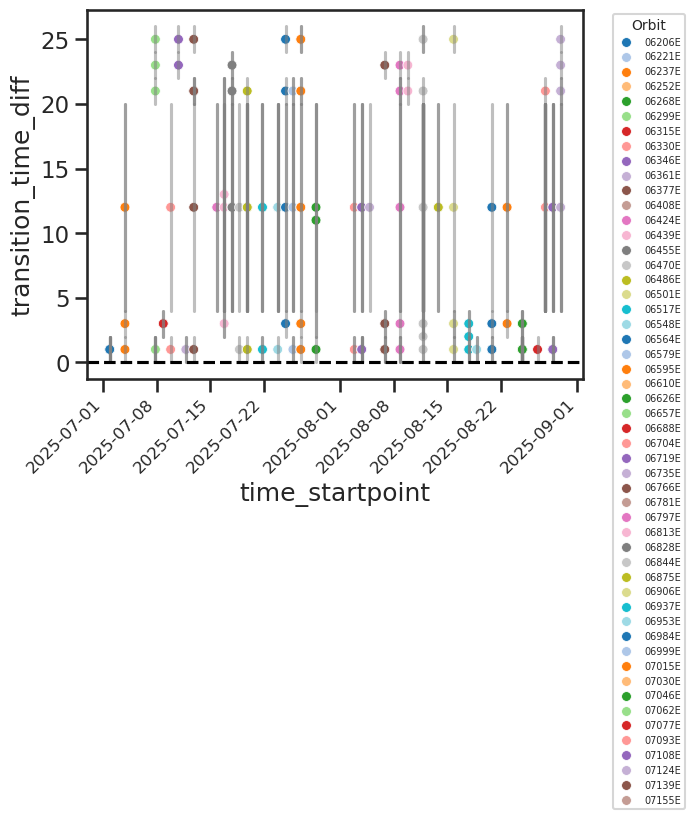

In [105]:
sns.scatterplot(data = bt_co_back_from_o, x='time_startpoint', y='transition_time_diff', hue='orbit', palette='tab20', legend=True, s=50)
plt.xticks(rotation=45, fontsize=12, ha='right')
# add whiskers for uncertainty
for i in range(len(bt_co_back_from_o.time_startpoint)):
    if not pd.isna(bt_co_back_from_o.transition_time_diff.values[i]):
        plt.plot([bt_co_back_from_o.time_startpoint.values[i], bt_co_back_from_o.time_startpoint.values[i]], 
                 [bt_co_back_from_o.transition_time_diff.values[i] - bt_co_back_from_o.transition_uncertainty.values[i],
                  bt_co_back_from_o.transition_time_diff.values[i] + bt_co_back_from_o.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)

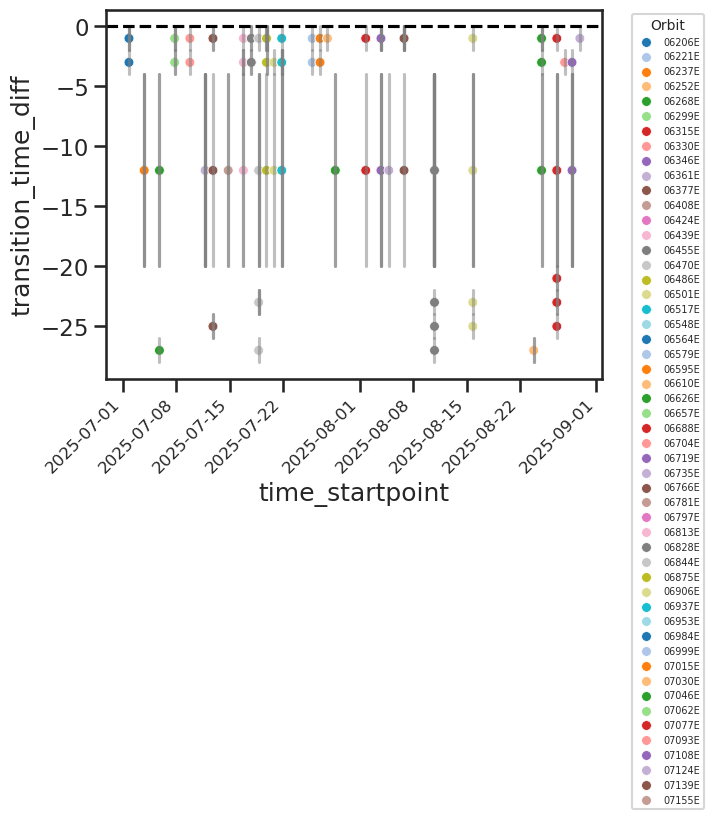

In [106]:
sns.scatterplot(data = bt_co_forward_from_c, x='time_startpoint', y='transition_time_diff', hue='orbit', palette='tab20', legend=True, s=50)
plt.xticks(rotation=45, fontsize=12, ha='right')
# add whiskers for uncertainty
for i in range(len(bt_co_forward_from_c.time_startpoint)):
    if not pd.isna(bt_co_forward_from_c.transition_time_diff.values[i]):
        plt.plot([bt_co_forward_from_c.time_startpoint.values[i], bt_co_forward_from_c.time_startpoint.values[i]], 
                 [bt_co_forward_from_c.transition_time_diff.values[i] - bt_co_forward_from_c.transition_uncertainty.values[i],
                  bt_co_forward_from_c.transition_time_diff.values[i] + bt_co_forward_from_c.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)

Transition statistics:
Trajectories with transitions: 61
Total trajectories: 1577


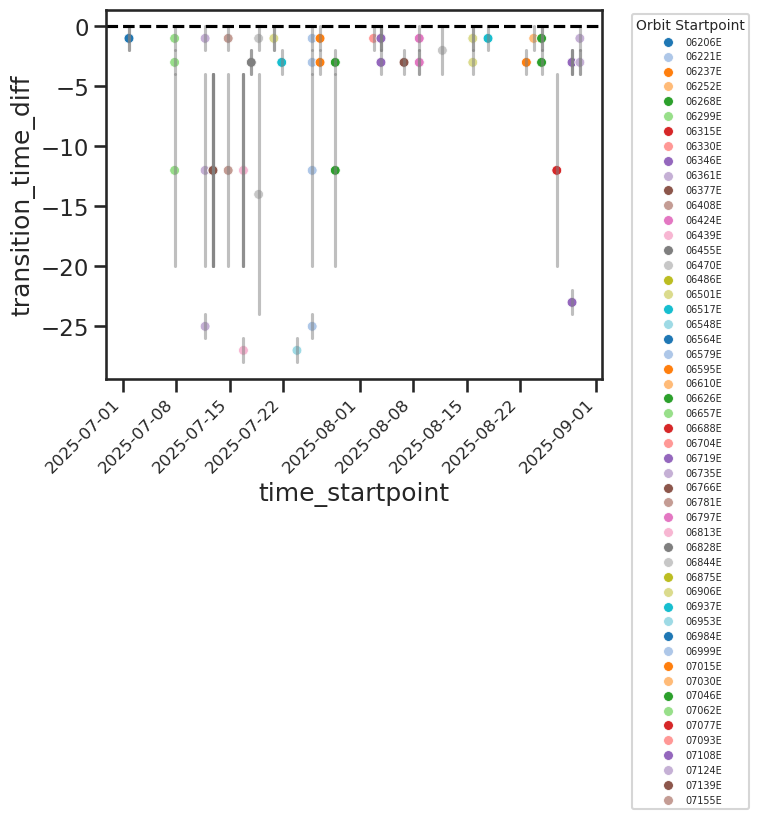

In [107]:
# O -> C transitions
bt_oc_forward_from_o = get_transition_properties(bt_O, transition_from_goes_cats=[2], transition_to_goes_cats=[0,1], backward=False)

# Check results
print("Transition statistics:")
print(f"Trajectories with transitions: {(~pd.isna(bt_oc_forward_from_o.transition_timestep.values)).sum()}")
print(f"Total trajectories: {len(bt_oc_forward_from_o.time_startpoint)}")


sns.scatterplot(data = bt_oc_forward_from_o, x='time_startpoint', y='transition_time_diff', hue='orbit', palette='tab20', legend=True, s=50)
plt.xticks(rotation=45, fontsize=12, ha='right')
# add whiskers for uncertainty
for i in range(len(bt_oc_forward_from_o.time_startpoint)):
    if not pd.isna(bt_oc_forward_from_o.transition_time_diff.values[i]):
        plt.plot([bt_oc_forward_from_o.time_startpoint.values[i], bt_oc_forward_from_o.time_startpoint.values[i]], 
                 [bt_oc_forward_from_o.transition_time_diff.values[i] - bt_oc_forward_from_o.transition_uncertainty.values[i],
                  bt_oc_forward_from_o.transition_time_diff.values[i] + bt_oc_forward_from_o.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit Startpoint', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)

### check transition detection visually

In [108]:
bt_co_back_from_o

<xarray.Dataset> Size: 6MB
Dimensions:                 (time_startpoint: 1577, timestep: 43)
Coordinates:
  * time_startpoint         (time_startpoint) datetime64[ns] 13kB 2025-07-01T...
  * timestep                (timestep) int64 344B -42 -40 -38 -36 ... 38 40 42
    orbit                   (time_startpoint) <U6 38kB '06206E' ... '07155E'
Data variables: (12/15)
    lat_traj                (time_startpoint, timestep) float64 542kB nan ......
    lon_traj                (time_startpoint, timestep) float64 542kB nan ......
    plev_traj               (time_startpoint, timestep) float64 542kB nan ......
    datetime_traj           (time_startpoint, timestep) datetime64[ns] 542kB ...
    goes_cats               (time_startpoint, timestep) float64 542kB nan ......
    goes_cert               (time_startpoint, timestep) float64 542kB nan ......
    ...                      ...
    goes_lon_mid            (time_startpoint, timestep) float64 542kB nan ......
    goes_lat_mid            (time_startpoint, timestep) float64 542kB nan ......
    transition_timestep     (time_startpoint) float64 13kB nan nan ... nan nan
    transition_datetime     (time_startpoint) datetime64[ns] 13kB NaT ... NaT
    transition_time_diff    (time_startpoint) float64 13kB nan nan ... nan nan
    transition_uncertainty  (time_startpoint) float64 13kB nan nan ... nan nan

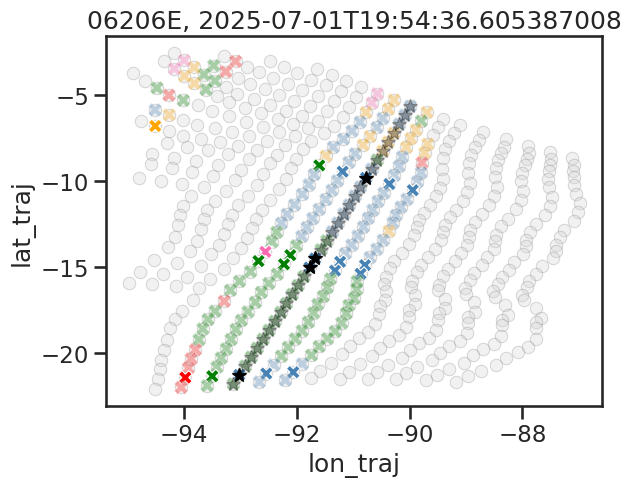

/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)


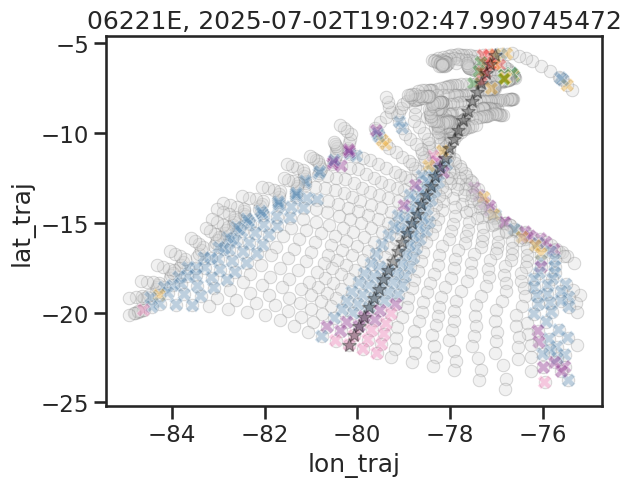

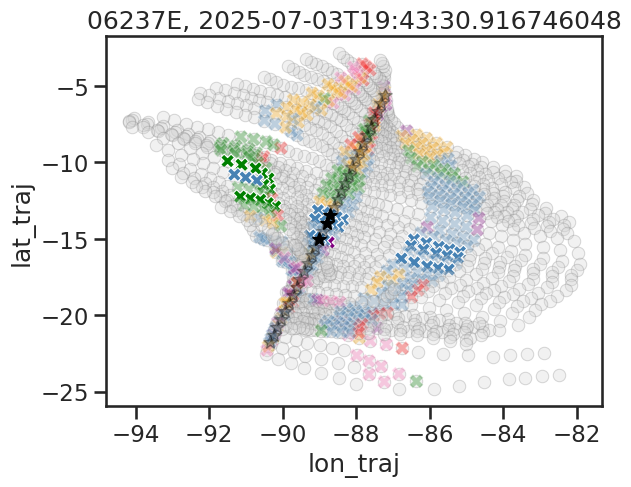

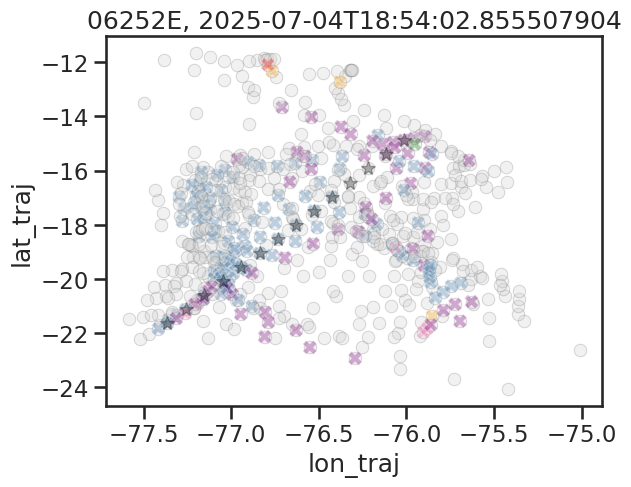

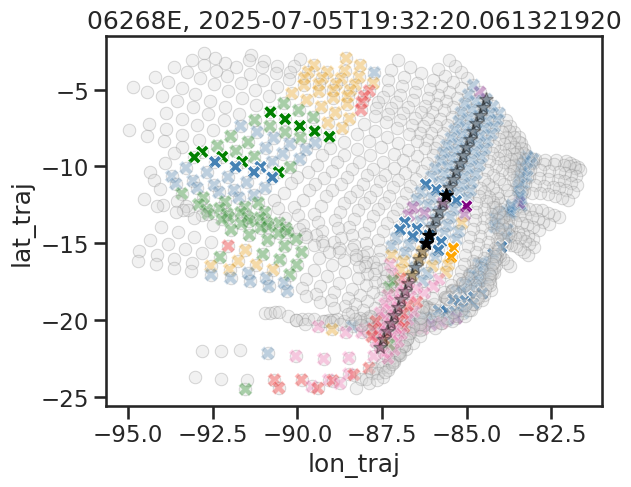

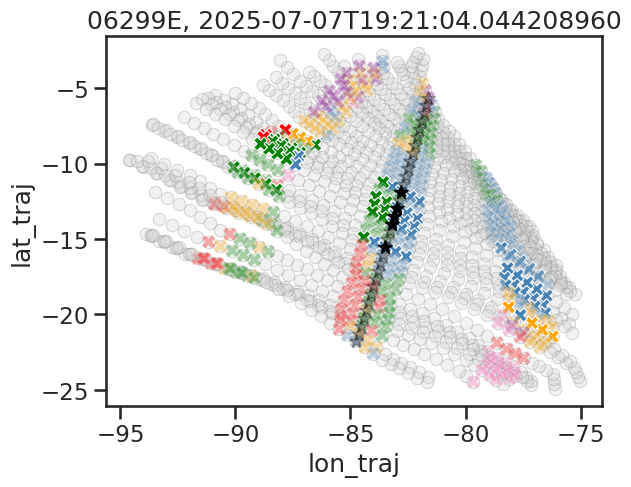

...

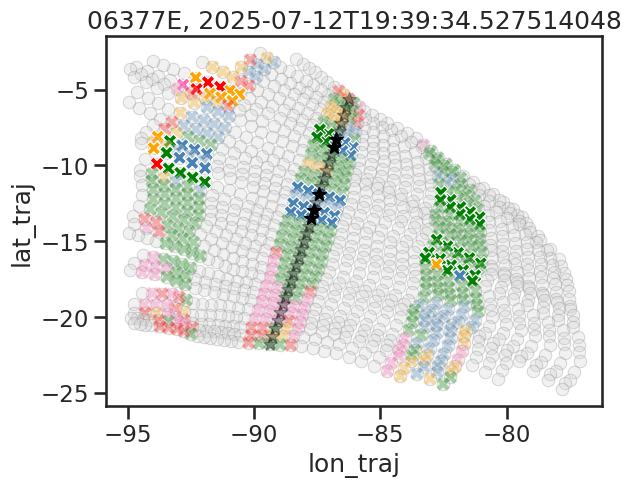

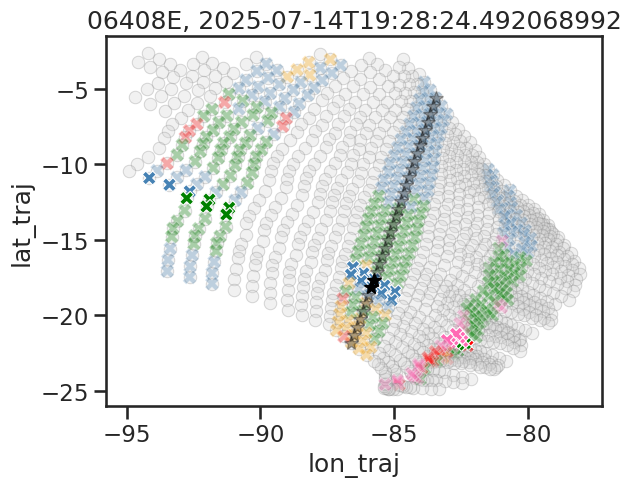

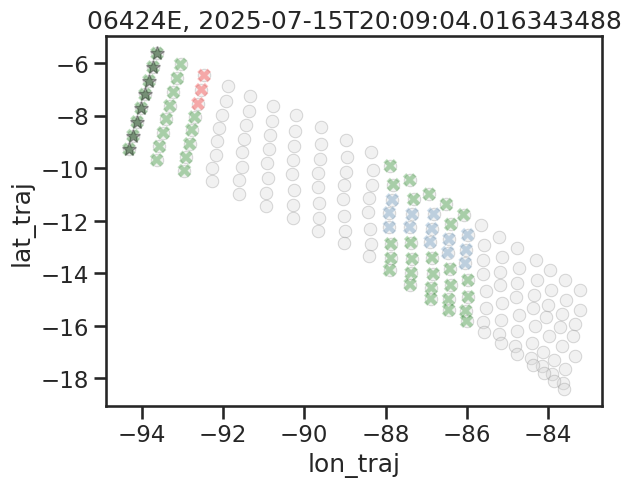

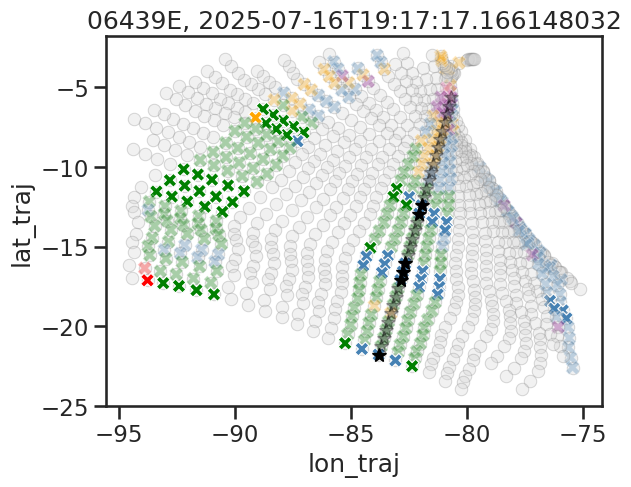

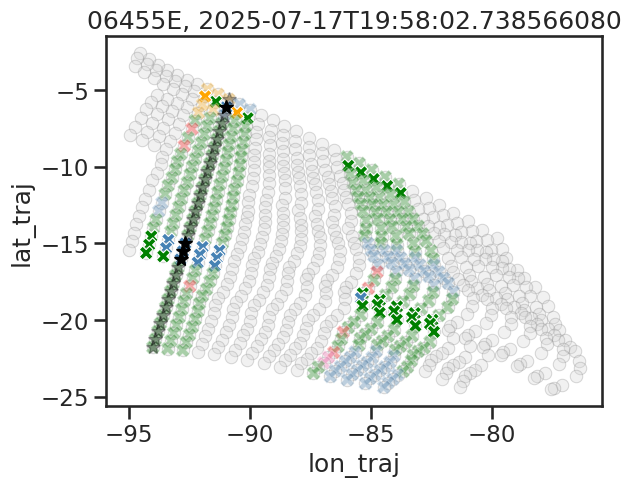

/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)


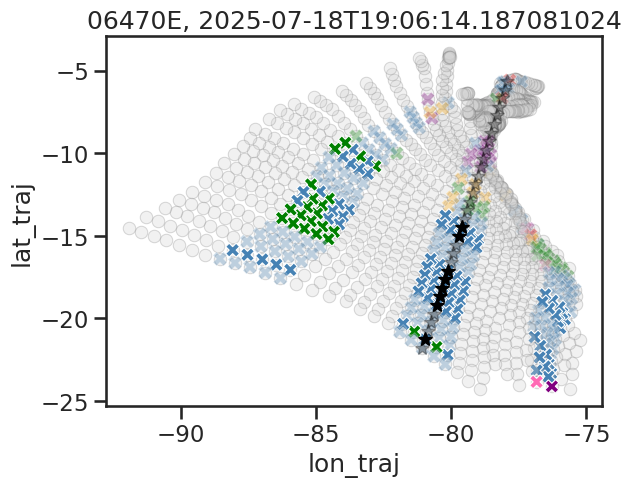

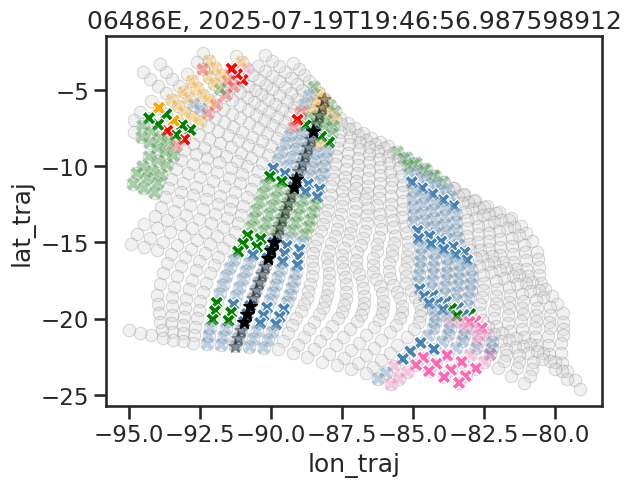

/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_g

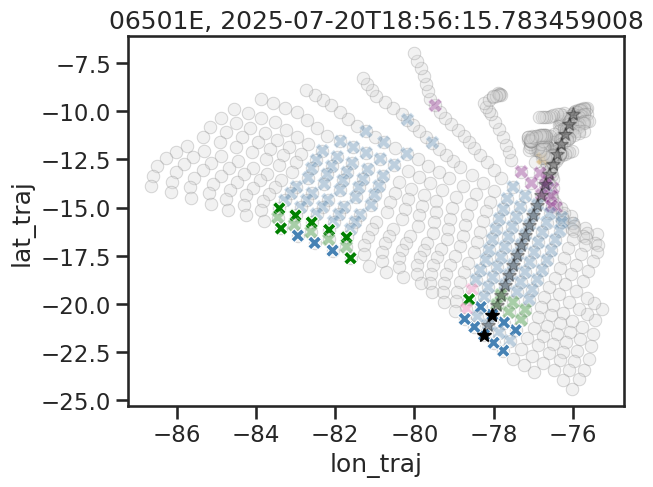

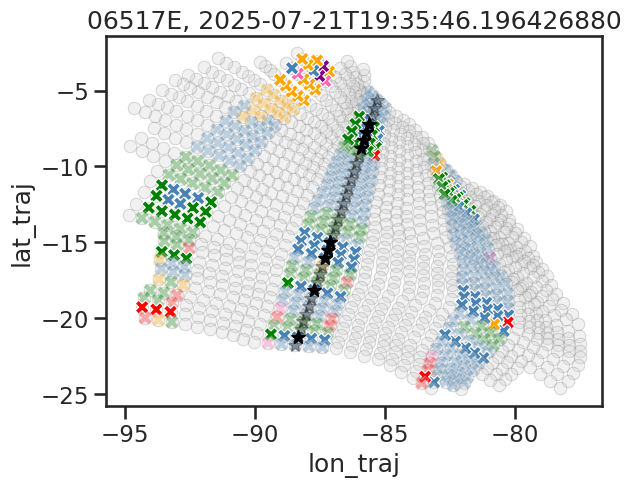

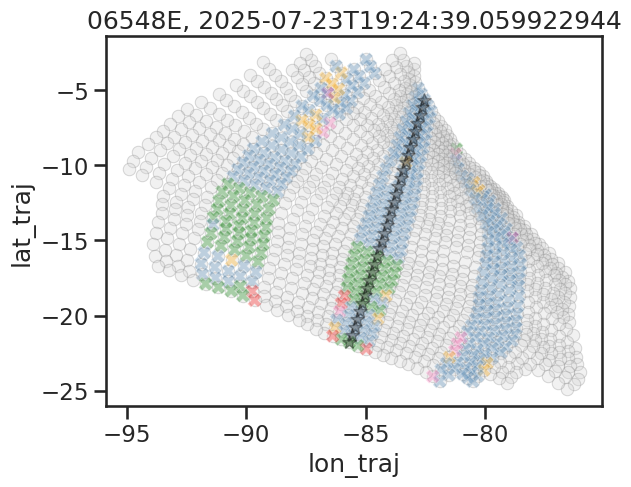

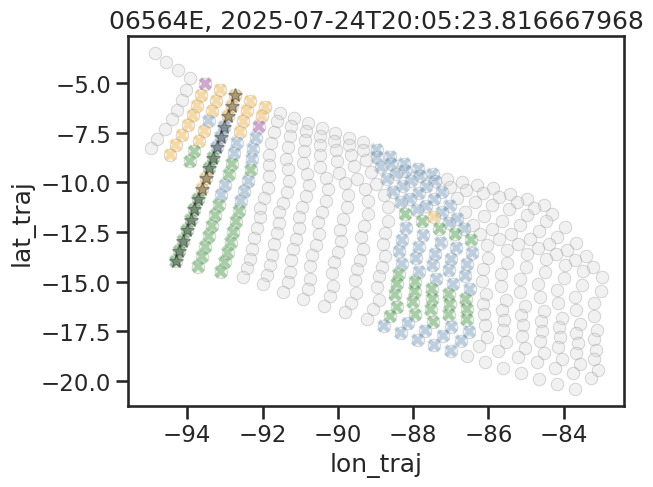

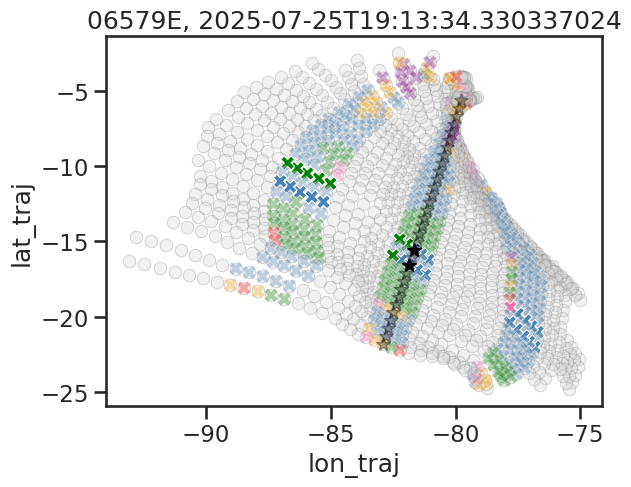

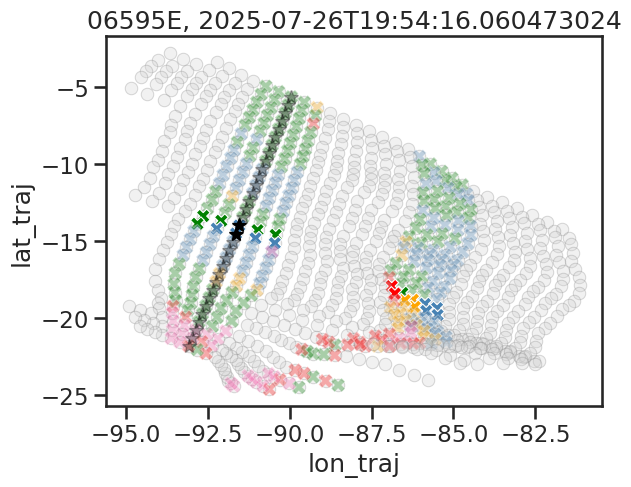

/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)


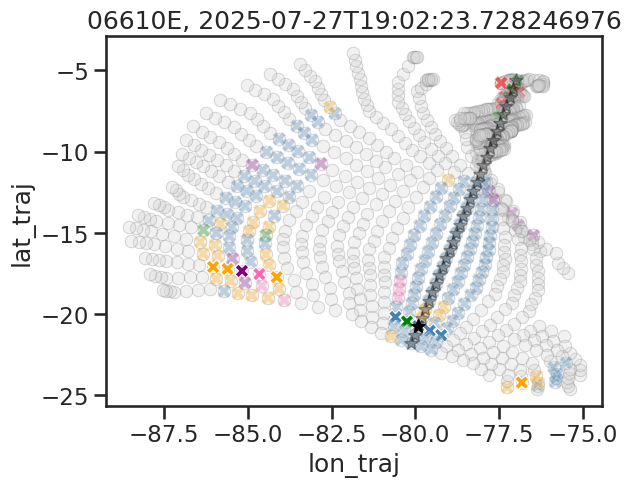

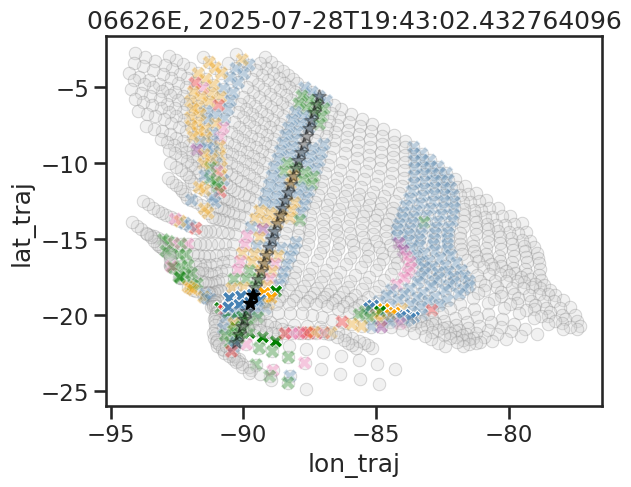

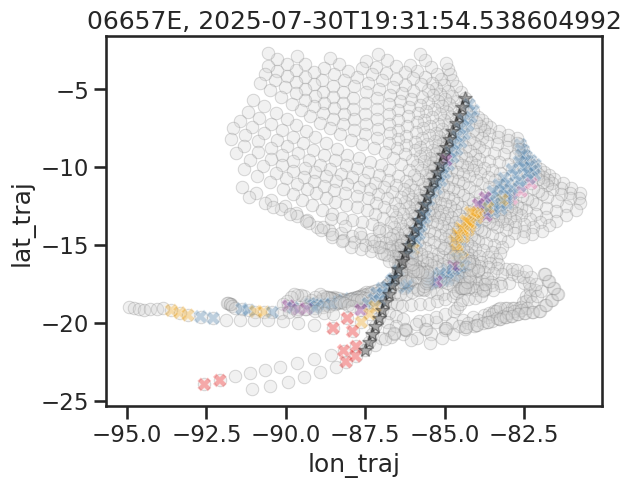

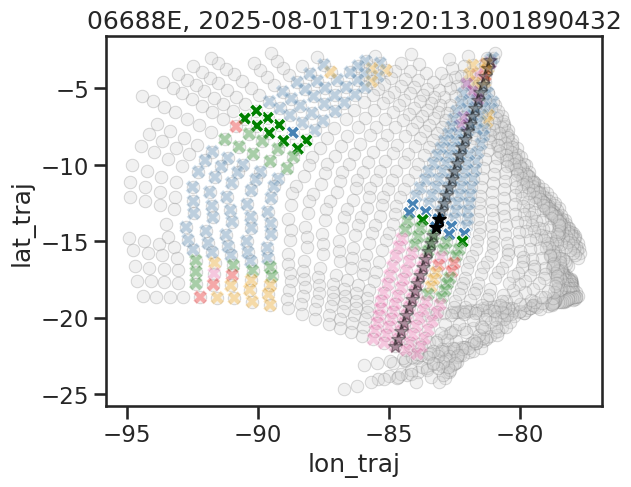

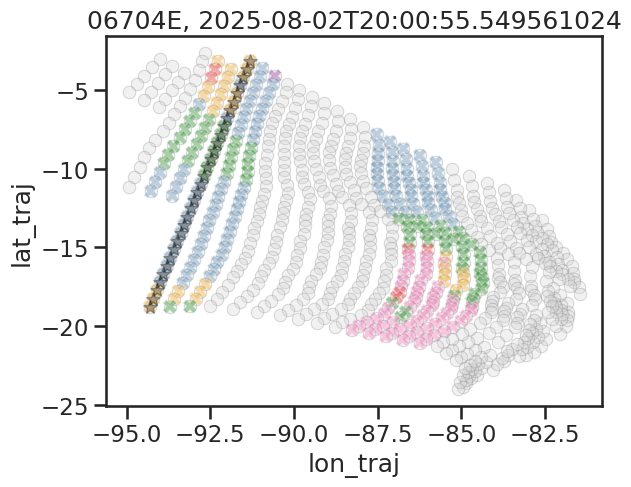

...

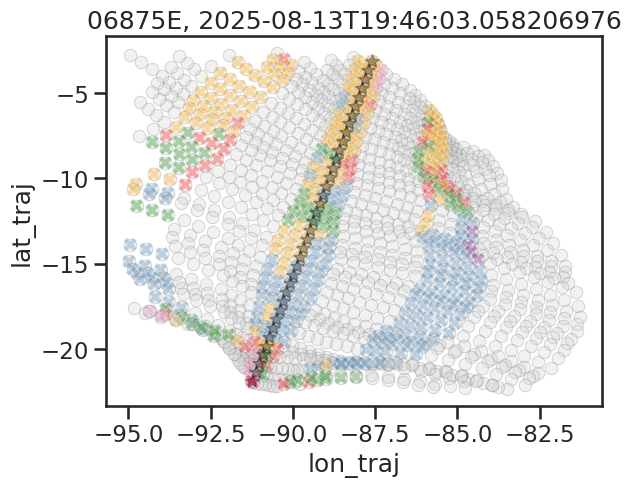

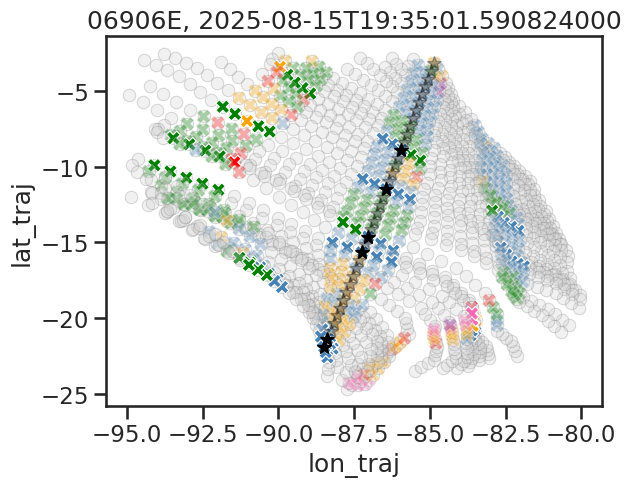

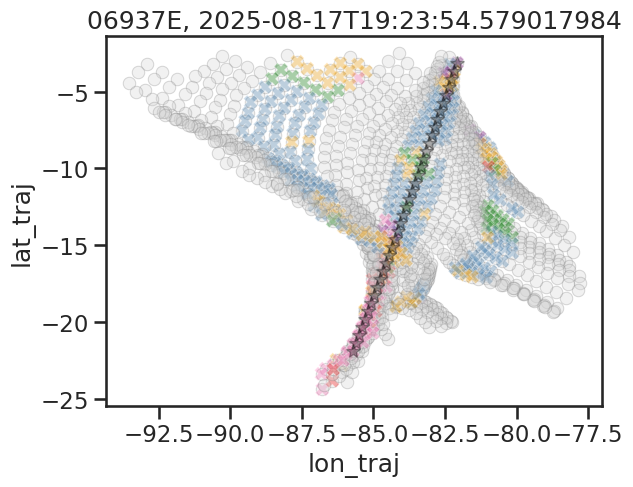

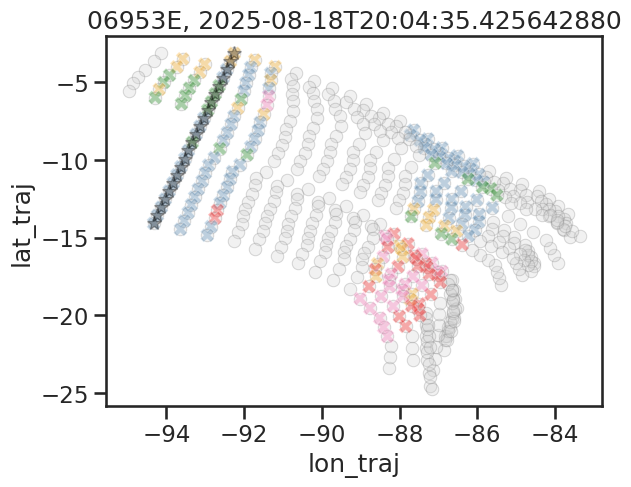

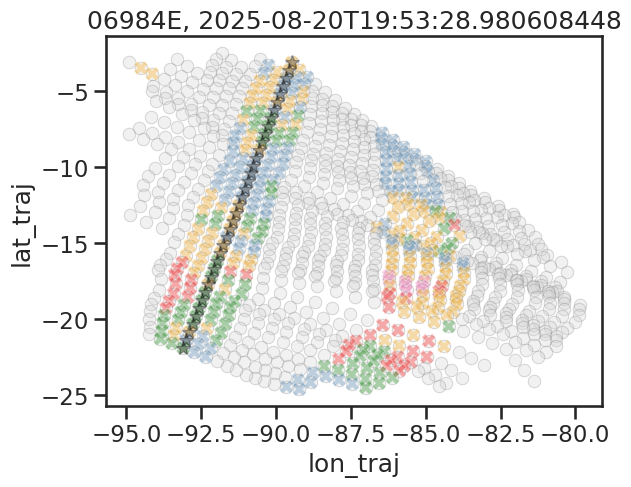

/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_g

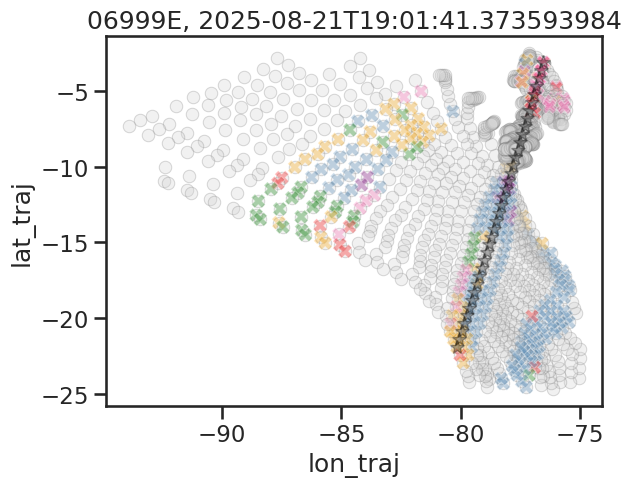

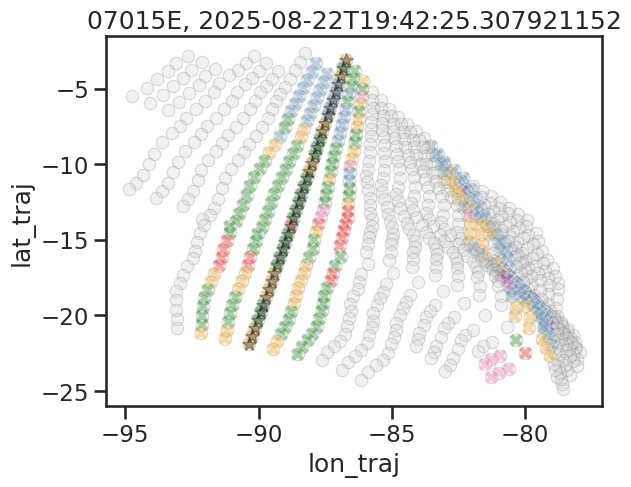

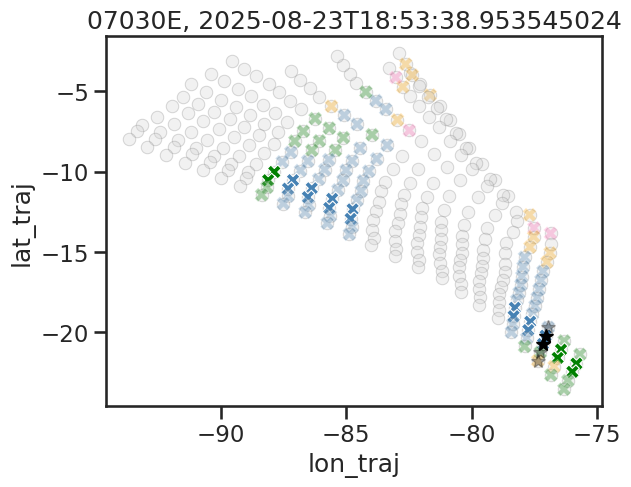

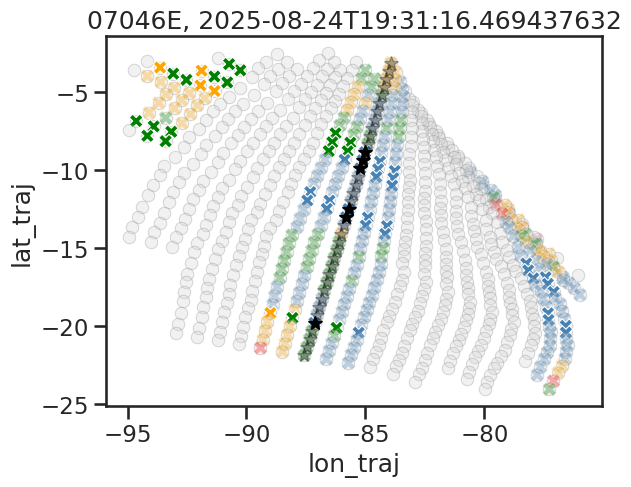

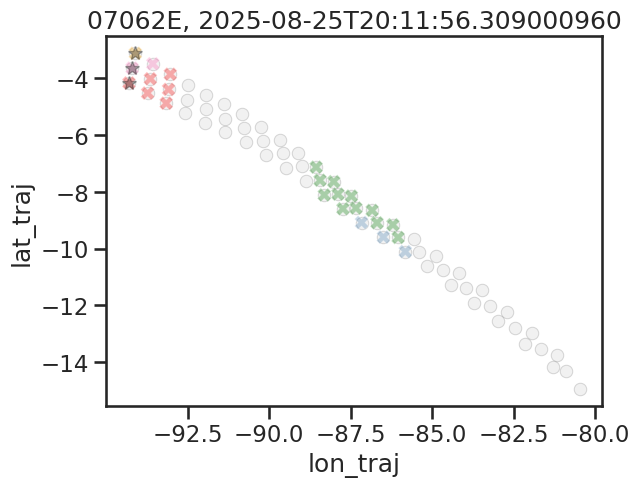

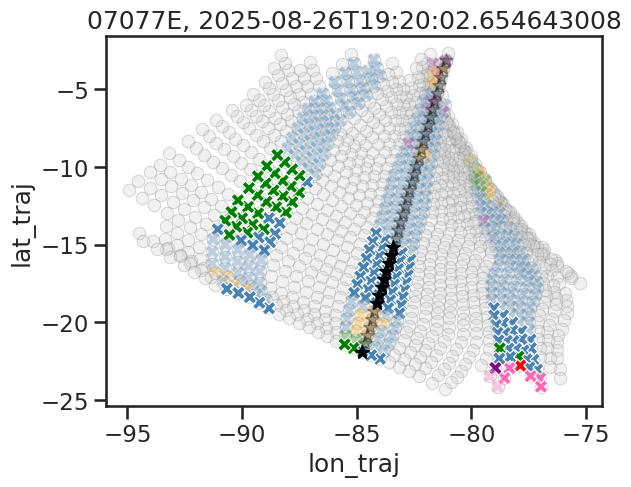

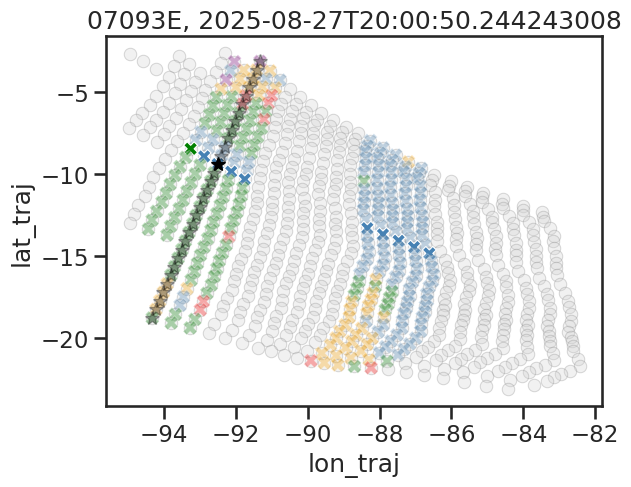

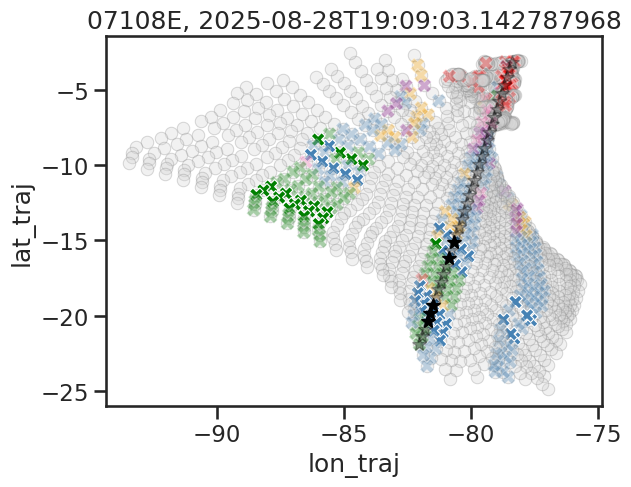

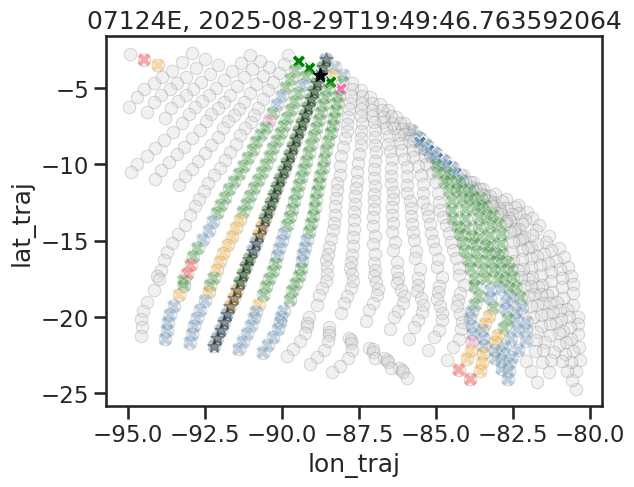

/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)


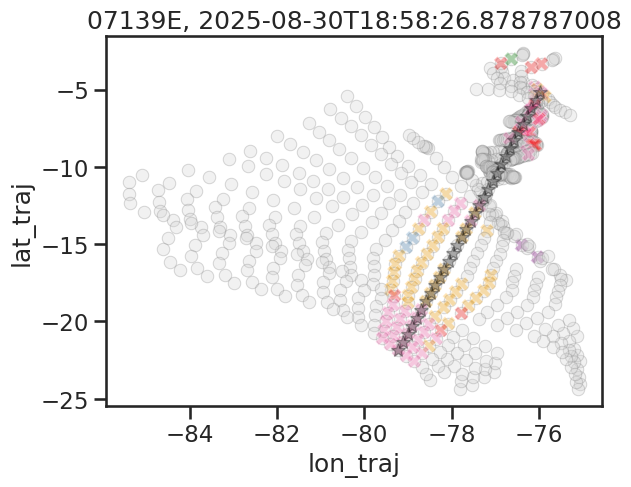

/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
/tmp/ipykernel_4192883/3426313123.py:17: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)


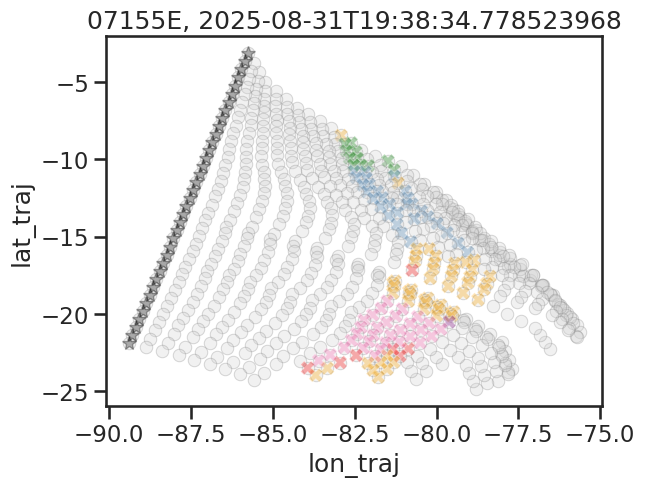

In [114]:
palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

ds_to_check = bt_co_forward_from_c #bt_co_back_from_o

for orbit in np.unique(ds_to_check.orbit):
    bt_orbit = ds_to_check.where(ds_to_check.orbit == orbit, drop=True)
    for i in range(len(bt_orbit.time_startpoint)):
        tmp = bt_orbit.isel(time_startpoint=i)
        if tmp.transition_flag == False:
            # no transition detected
            alpha = 0.3
        else:
            # transition detected
            alpha = 1.0
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', color='lightgrey', alpha=0.3, edgecolor='Grey', legend=False)
        plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], color='black', marker='*', markersize=10, alpha=alpha)
        sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100, marker='X', alpha=alpha)
    plt.title(f'{orbit}, {bt_orbit.time_startpoint.values[0]}')
    plt.show()

## add ACMCAP information

In [38]:
acmcap_dataset_filename = '/home/jmayer/ACI_research/Code/resources/ACMCAP_XMET_judge_StCu_Jun-Aug.h5'
acmcap = pd.read_hdf(acmcap_dataset_filename, key='StCu')

In [111]:
acmcap.head()

,along_track,time,latitude,longitude,stratus_region_index,lwp,ER,ER_passive_perspective,Nd,lwp_error,...,ice_flag_0,ice_flag_1,scene_id_0,scene_id_1,MCOP_cloud_cover_judge_0,MCOP_cloud_cover_judge_1,MCOP_cwp_skew_judge_0,MCOP_cwp_skew_judge_1,MCOP_cwp_inhomogeneity_judge_0,MCOP_cwp_inhomogeneity_judge_1
0,2981,2025-06-01 13:26:02.599795968,-5.001905,7.111185,0,0.000051,8.760879e-07,8.760849e-07,54752600.0,0.478148,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1,2982,2025-06-01 13:26:02.736145920,-5.010733,7.109528,0,0.007185,4.358948e-06,4.684363e-06,55660160.0,0.330290,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
2,2983,2025-06-01 13:26:02.872495872,-5.019562,7.107870,0,0.000300,1.552164e-06,1.558314e-06,57090188.0,0.479258,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
3,2984,2025-06-01 13:26:03.008845952,-5.028391,7.106212,0,0.011196,4.916011e-06,5.970363e-06,62343752.0,0.341860,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
4,2985,2025-06-01 13:26:03.190764032,-5.040170,7.104001,0,0.025249,6.399618e-06,6.650821e-06,65047464.0,0.376912,...,-1.0,-1.0,-1,-1,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0


In [ ]:
acmcap.MCOP

Index(['along_track', 'time', 'latitude', 'longitude', 'stratus_region_index',
       'lwp', 'ER', 'ER_passive_perspective', 'Nd', 'lwp_error', 'Nd_error',
       'liquid_classification_mean', 'liquid_optical_depth', 'cth', 'cbh',
       'cth_m', 'cbh_m', 'cth_all_clouds', 'multilayer', 'N_cloudy_pixels',
       'N_high_cc', 'rain_rate_surface', 'rain_rate_cbh', 'rain_rate_max',
       'rain_rate_subcloud', 'doppler_velocity_mean', 'cbh_min_max_128km',
       'cbh_minus_lcl', 'CPR_path_integrated_attenuation', 'MSI_BT_108',
       'boundary_layer_height', 'lcl', 'sea_surface_temperature',
       'total_column_water_vapour', 'lower_tropospheric_stability',
       'inversion_strength', 'relative_humidity_below_bl',
       'relative_humidity_above_bl', 'relative_humidity_below_cth',
       'relative_humidity_above_cth', 'relative_humidity_at_3km',
       'upward_air_velocity_at_3km', 'MCOP_effective_radius',
       'MCOP_optical_thickness', 'MCOP_cloud_water_path', 'MCOP_cwp_skew_256',
  

In [156]:
def add_acmcap_info_to_bt(bt_dataset, acmcap, judge_SEP, peek_at_acmcap_clouds = False):
    """
    For each trajectory startpoint in bt_dataset, find the corresponding ACMCAP scene(s)
    based on orbit and time, and extract rain rate and other properties if the CATS
    match the specified transition_from_goes_cats.

    Parameters:
    -----------
    bt_dataset : xarray.Dataset
        Dataset with orbit_startpoint and time_startpoint variables
    acmcap : pandas.DataFrame
        ACMCAP dataset with orbit, time, scene_id, cats, rain_rate_cbh, etc.
    judge_SEP : pandas.DataFrame
        DataFrame with judge_SEP window information including lat_min and lat_max

    Returns:
    --------
    xarray.Dataset
        Dataset with added variables for rain rate and other properties
    """
    # get rain water path for ACMCAP judge scenes, matching the time_startpoints in bt_O_orbit
    rr_array = []
    std_rr_array = []
    max_rr_array = []
    rwp_array = []
    rwp_given_cloud_array = []
    std_rwp_array = []
    lwp_array = []
    nd_array = []
    cth_m_array = []
    max_cth_m_array = []
    cbh_m_array = []
    cbh_minus_lcl_array = []
    mcop_cc_array = []
    sst_array = []
    lts_array = []

    failed_time_startpoints = []
    for t_ in bt_dataset.time_startpoint.values:
        # skip if no transition was detected
        trans_flag = bt_dataset.sel(time_startpoint=t_).transition_flag
        if trans_flag == False:
            rr = np.nan
            std_rr = np.nan
            max_rr = np.nan
            rwp = np.nan
            rwp_given_cloud = np.nan
            std_rwp = np.nan
            lwp = np.nan
            nd = np.nan
            cth_m = np.nan
            max_cth_m = np.nan
            cbh_m = np.nan
            cbh_minus_lcl = np.nan
            mcop_cc = np.nan
            sst = np.nan
            lts = np.nan

        elif trans_flag == True:
            print(t_)
            orbit = bt_dataset.sel(time_startpoint=t_).orbit.values

            # get window extent (lat_min, lat_max) from judge_SEP
            judge_SEP_window = judge_SEP[(judge_SEP.orbit == orbit) & (np.abs(pd.to_datetime(judge_SEP.time_mid) - pd.to_datetime(t_)) < pd.Timedelta('0.1s'))]
            if len(judge_SEP_window) == 0:
                print(f'No judge_SEP window found for orbit {orbit} and time {t_}, skipping...')
                failed_time_startpoints.append(t_)
                continue
            elif len(judge_SEP_window) > 1:
                print(f'Multiple judge_SEP windows found for orbit {orbit} and time {t_}, using first one...')
                judge_SEP_window = judge_SEP_window.iloc[0:1]
            lat_min_window = judge_SEP_window.lat_min.values[0]
            lat_max_window = judge_SEP_window.lat_max.values[0]

            # get acmcap data in window around time_startpoint
            acmcap_orbit = acmcap[acmcap.orbit == orbit]
            acmcap_window = acmcap_orbit[(acmcap_orbit.latitude >= lat_min_window) & (acmcap_orbit.latitude <= lat_max_window)]
            acmcap_time_startpoint = acmcap_orbit[np.abs(pd.to_datetime(acmcap_orbit.time) - pd.to_datetime(t_)) < pd.Timedelta('0.1s')]

            # get ACMCAP values
            rr = acmcap_window.rain_rate_cbh.mean()
            if np.isnan(rr):
                rr = 0
            std_rr = acmcap_window.rain_rate_cbh.std()
            max_rr = acmcap_window.rain_rate_cbh.max()
            rwp = acmcap_window.rwp.mean()
            rwp_given_cloud = acmcap_window[acmcap_window.lwp > 0].rwp.mean()
            std_rwp = acmcap_window.rwp.std()
            lwp = acmcap_window.lwp.mean()
            nd = acmcap_window.Nd.mean()
            cth_m = acmcap_window.cth_m.mean()
            max_cth_m = acmcap_window.cth_m.max()
            cbh_m = acmcap_window.cbh_m.mean()
            cbh_minus_lcl = acmcap_window.cbh_minus_lcl.mean()
            mcop_cc = acmcap_window.MCOP_cloud_cover_judge_0.mean()
            sst = acmcap_window.sea_surface_temperature.mean()
            lts = acmcap_window.lower_tropospheric_stability.mean()

            
        rr_array.append(rr)
        std_rr_array.append(std_rr)
        max_rr_array.append(max_rr)
        rwp_array.append(rwp)
        rwp_given_cloud_array.append(rwp_given_cloud)
        std_rwp_array.append(std_rwp)
        lwp_array.append(lwp)
        nd_array.append(nd)
        cth_m_array.append(cth_m)
        max_cth_m_array.append(max_cth_m)
        cbh_m_array.append(cbh_m)
        cbh_minus_lcl_array.append(cbh_minus_lcl)
        mcop_cc_array.append(mcop_cc)
        sst_array.append(sst)
        lts_array.append(lts)

        if peek_at_acmcap_clouds:
            time_to_trans = bt_dataset.sel(time_startpoint=t_).transition_time_diff.values
            if trans_flag == False:
                continue

            tmp_scene = acmcap_window

            def add_profile(profile_arr, cbh_m, cth_m):
                # between dfex.cbh_m and dfex.cth_m (both arrays of size 113), the profile_arr should be filled with 1
                for i in range(len(cth_m)):
                    cbh = cbh_m.values[i]
                    cth = cth_m.values[i]
                    if np.isnan(cbh) or np.isnan(cth):
                        continue
                    cbh_idx = int(cbh // 100)
                    cth_idx = int(cth // 100)
                    # Ensure indices are within bounds
                    cbh_idx = max(0, min(cbh_idx, profile_arr.shape[1] - 1))
                    cth_idx = max(0, min(cth_idx, profile_arr.shape[1] - 1))
                    profile_arr[i, cbh_idx:cth_idx+1] += 1
                return profile_arr
            
            x_length = len(tmp_scene.latitude)
            profile_arr = xr.DataArray(np.zeros((x_length, 25)), dims=['latitude', 'height'], coords={'latitude': tmp_scene.latitude.values, 'height': np.arange(25)*100})
            profile_arr = add_profile(profile_arr, tmp_scene.cbh_m, tmp_scene.cth_m)
            sns.set_style('white')
            sns.set_context('talk', font_scale=0.8)
            fig, axs = plt.subplots(2, 1, figsize=(x_length/100*5, 4))
            ax=axs[0]
            im1 = ax.imshow(profile_arr.T, origin='lower', aspect='auto', extent=[0,x_length,0,2500], cmap='Blues_r')
            im2 = ax.imshow((profile_arr * tmp_scene.rain_rate_cbh.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2500], cmap='chiljet2', norm=LogNorm(1e-7, 1e-4))
            plt.colorbar(im2, ax=ax, label='RR / kg m$^{-2}$ s$^{-1}$')
            ax.set_xticks(ticks=np.linspace(0, x_length, 3), labels=[f'{lat:.2f}' for lat in np.linspace(tmp_scene.latitude.values[0], tmp_scene.latitude.values[-1], 3)])
            ax.set_title(f'{orbit}, $\Delta$t={time_to_trans}')
            ax = axs[1]
            im3 = ax.imshow(profile_arr.T, origin='lower', aspect='auto', extent=[0,x_length,0,2500], cmap='Blues_r')
            im4 = ax.imshow((profile_arr * tmp_scene.lwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2500], cmap='chiljet2', norm=LogNorm(1e-4, 1e0))
            plt.colorbar(im4, ax=ax, label='LWP / kg m$^{-2}$')
            ax.set_xticks(ticks=np.linspace(0, x_length, 3), labels=[f'{lat:.2f}' for lat in np.linspace(tmp_scene.latitude.min(), tmp_scene.latitude.max(), 3)])
            fig.tight_layout()
            plt.show()

            #plt.figure(figsize=(9, 2.5))
            #ax = plt.gca()
            ## Use pandas plotting instead of seaborn to avoid coordinate issues
            #ax.plot(tmp_scene.latitude, tmp_scene.cth_m, color='blue')
            #ax.plot(tmp_scene.latitude, tmp_scene.cbh_m, color='blue')
            #ax2 = ax.twinx()
            #ax2.plot(tmp_scene.latitude, tmp_scene.rain_rate_cbh, color='red')
            #ax.set_xlabel('Latitude')
            #ax.set_ylabel('Height (m)')
            #ax.set_ylim(0, 1500)
            #plt.title(f'Orbit {orbit}, time to trans. {time_to_trans} Scene ID {scene_id}')
            #plt.show()

    bt_dataset['rain_rate_cbh'] = xr.DataArray(rr_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['std_rain_rate_cbh'] = xr.DataArray(std_rr_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['max_rain_rate_cbh'] = xr.DataArray(max_rr_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['rwp'] = xr.DataArray(rwp_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['rwp_given_cloud'] = xr.DataArray(rwp_given_cloud_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['std_rwp'] = xr.DataArray(std_rwp_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['lwp'] = xr.DataArray(lwp_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['nd'] = xr.DataArray(nd_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['cth_m'] = xr.DataArray(cth_m_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['max_cth_m'] = xr.DataArray(max_cth_m_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['cbh_m'] = xr.DataArray(cbh_m_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['H'] = bt_dataset.cth_m - bt_dataset.cbh_m
    bt_dataset['cbh_minus_lcl'] = xr.DataArray(cbh_minus_lcl_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['mcop_cc'] = xr.DataArray(mcop_cc_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['sst'] = xr.DataArray(sst_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})
    bt_dataset['lts'] = xr.DataArray(lts_array, dims='time_startpoint', coords={'time_startpoint': bt_dataset.time_startpoint.values})

    print(f'Failed to find EC window data for {len(failed_time_startpoints)} time_startpoints: {failed_time_startpoints}')

    return bt_dataset

<>:149: SyntaxWarning: invalid escape sequence '\D'
<>:149: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_4192883/2601313677.py:149: SyntaxWarning: invalid escape sequence '\D'
  ax.set_title(f'{orbit}, $\Delta$t={time_to_trans}')


### CO transitions

In [157]:
bt_co_forward_from_c = add_acmcap_info_to_bt(bt_co_forward_from_c, acmcap, judge_SEP)

bt_co_back_from_o = add_acmcap_info_to_bt(bt_co_back_from_o, acmcap, judge_SEP)

2025-07-01T19:55:41.117903104
2025-07-01T19:56:53.694474880
2025-07-01T19:57:01.758539136
2025-07-01T19:58:38.527308928
2025-07-03T19:45:31.877705984
2025-07-03T19:45:39.941769024
2025-07-03T19:45:56.069903104
2025-07-05T19:33:56.830085120
2025-07-05T19:34:37.150409088
2025-07-05T19:34:45.214473088
2025-07-07T19:22:40.812988032
2025-07-07T19:22:56.941117952
2025-07-07T19:23:05.005186496
2025-07-07T19:23:13.069254976
2025-07-07T19:23:37.261449984
2025-07-09T19:12:03.291561088
2025-07-09T19:12:11.355624064
2025-07-11T19:02:29.015899520
2025-07-11T19:02:37.079966400
2025-07-11T19:02:45.144030080
2025-07-11T19:02:53.208094080
2025-07-11T19:03:01.272157120
2025-07-12T19:40:14.847831936
2025-07-12T19:40:22.911895872
2025-07-12T19:41:11.296283072
2025-07-12T19:41:27.424411008
2025-07-12T19:41:35.488473984
2025-07-14T19:31:29.965537920
2025-07-14T19:31:38.029604416
2025-07-16T19:19:01.998978048
2025-07-16T19:19:10.063044992
2025-07-16T19:19:58.447426048
2025-07-16T19:20:06.511489920
2025-07-16

#### ACMCAP profiles of CO transitioning clouds

2025-08-01T19:22:30.090981056
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:38.155044992
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:46.219108544
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:54.283171968
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-02T20:02:56.510521024
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-02T20:03:04.574584064
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-02T20:03:12.638648000
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-03T19:11:29.252185024
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-03T19:11:37.316248000
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-03T19:11:45.380312064
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-03T19:11:53.444374912
CATS_0 = [0, 1] match confirme

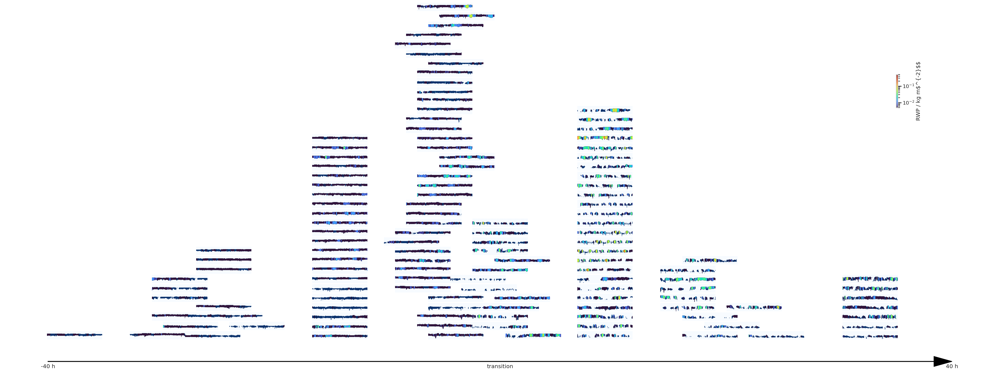

In [ ]:
# create a big figure with many small subplots (like peek_at_acmcap) to compare the different trajectory sets
# the subplots are at x-positions determined by the transition_time_diff values, and y-positions determined s.t. plots dont overlap
hue_variable = 'rwp'  # can be 'rain_rate_cbh', 'lwp'

fig = plt.figure(figsize=(40, 20))
# Track occupied positions to avoid overlaps
occupied_positions = []  # List of (left, right, bottom, top) rectangles
subplot_width = 0.05
subplot_height = 0.015

#transition_times = bt_dataset.transition_time_diff.values
#valid_times = transition_times[~np.isnan(transition_times)]
#time_min, time_max = valid_times.min(), valid_times.max()
time_min, time_max = -40, 40

sns.set_context('talk', font_scale=0.8)

for bt_dataset, transition_from_msi_cats in [
    (bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True), [0, 1]),
    (bt_co_back_from_o.where(~np.isnan(bt_co_back_from_o.transition_time_diff), drop=True), [2])
    ]:


    for i, t_ in enumerate(bt_dataset.time_startpoint.values):
        print(t_)
        orbit = bt_dataset.sel(time_startpoint=t_).orbit_startpoint.values
        acmcap_orbit = acmcap[acmcap.orbit == orbit]
        acmcap_time_startpoint = acmcap_orbit[np.abs(pd.to_datetime(acmcap_orbit.time) - pd.to_datetime(t_)) < pd.Timedelta('0.1s')]
        # check
        scene_0_matches = False
        scene_1_matches = False
        if np.isin(np.unique(acmcap_time_startpoint.cats_0), transition_from_msi_cats):
            print(f'CATS_0 = {transition_from_msi_cats} match confirmed')
            scene_0_matches = True
            scene_id_0 = np.unique(acmcap_time_startpoint.scene_id_0)
        if np.isin(np.unique(acmcap_time_startpoint.cats_1), transition_from_msi_cats):
            print(f'CATS_1 = {transition_from_msi_cats} match confirmed')
            scene_1_matches = True
            scene_id_1 = np.unique(acmcap_time_startpoint.scene_id_1)

        time_to_trans = bt_dataset.sel(time_startpoint=t_).transition_time_diff.values
        if pd.isna(time_to_trans):
            continue

        if scene_0_matches and scene_1_matches:
            acmcap_orbit_0 = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0[0]]
            tmp_latmax, tmp_latmin = acmcap_orbit_0.latitude.max(), acmcap_orbit_0.latitude.min()
            acmcap_orbit_1 = acmcap_orbit[(acmcap_orbit.scene_id_1 == scene_id_1[0]) & ((acmcap_orbit.latitude > tmp_latmax) | (acmcap_orbit.latitude < tmp_latmin))]  # remove overlapping latitudes
            tmp_scene = pd.concat([acmcap_orbit_0, acmcap_orbit_1])
            tmp_scene = tmp_scene.sort_values(by='latitude')
            scene_id = f'{scene_id_0[0]} & {scene_id_1[0]}'
        elif scene_0_matches:
            tmp_scene = acmcap_orbit[acmcap_orbit.scene_id_0 == scene_id_0[0]]
            scene_id = f'{scene_id_0[0]}'
        elif scene_1_matches:
            tmp_scene = acmcap_orbit[acmcap_orbit.scene_id_1 == scene_id_1[0]]
            scene_id = f'{scene_id_1[0]}'
        else:
            continue  # Skip plotting if no matches

        def add_profile(profile_arr, cbh_m, cth_m):
            # between dfex.cbh_m and dfex.cth_m (both arrays of size 113), the profile_arr should be filled with 1
            for i in range(len(cth_m)):
                cbh = cbh_m.values[i]
                cth = cth_m.values[i]
                if np.isnan(cbh) or np.isnan(cth):
                    continue
                cbh_idx = int(cbh // 100)
                cth_idx = int(cth // 100)
                # Ensure indices are within bounds
                cbh_idx = max(0, min(cbh_idx, profile_arr.shape[1] - 1))
                cth_idx = max(0, min(cth_idx, profile_arr.shape[1] - 1))
                profile_arr[i, cbh_idx:cth_idx+1] += 1
            return profile_arr
        
        x_length = len(tmp_scene.latitude)
        profile_arr = xr.DataArray(np.zeros((x_length, 20)), dims=['latitude', 'height'], coords={'latitude': tmp_scene.latitude.values, 'height': np.arange(20)*100})
        profile_arr = add_profile(profile_arr, tmp_scene.cbh_m, tmp_scene.cth_m)


        # add axes to the big figure at the correct position
        # Calculate normalized position
        #norm_x = (time_to_trans - time_min) / (time_max - time_min)
        ## Position the subplot
        #left = 0.1 + norm_x * 0.8  # Use 80% of figure width
        #bottom = 0.1 + (i % 5) * 0.15  # Stack multiple rows if needed
        #width = 0.15
        #height = 0.05
        #ax = fig.add_axes([left, bottom, width, height])
        
        # Calculate normalized x position
        norm_x = (time_to_trans - time_min) / (time_max - time_min)
        left = 0.1 + norm_x * 0.8  # Use 80% of figure width
        right = left + subplot_width
        
        # Find available vertical position
        bottom = 0.1  # Start from bottom
        found_position = False
        
        while not found_position:
            top = bottom + subplot_height
            
            # Check if this position overlaps with any existing subplot
            overlaps = False
            for occupied in occupied_positions:
                occ_left, occ_right, occ_bottom, occ_top = occupied
                
                # Check for overlap
                if (left < occ_right and right > occ_left and 
                    bottom < occ_top and top > occ_bottom):
                    overlaps = True
                    break
            
            if not overlaps:
                found_position = True
            else:
                bottom += subplot_height + 0.002  # Move up with small gap
        
        # Record this position as occupied
        occupied_positions.append((left, right, bottom, top))
        
        # Create the subplot
        ax = fig.add_axes([left, bottom, subplot_width, subplot_height])
        
        im1 = ax.imshow(profile_arr.T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='Blues')
        if hue_variable == 'rwp':
            im2 = ax.imshow((profile_arr * tmp_scene.rwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='turbo', norm=LogNorm(5e-3, 5e-1))
            #plt.colorbar(im2, ax=ax, label='RR / kg m$^{-2}$ s$^{-1}$')
        elif hue_variable == 'lwp':
            im2 = ax.imshow((profile_arr * tmp_scene.lwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='viridis', norm=LogNorm(1e-4, 5e-1))
            #plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
        #ax.set_xticks(ticks=np.linspace(0, x_length, 3), labels=[f'{lat:.2f}' for lat in np.linspace(tmp_scene.latitude.values[0], tmp_scene.latitude.values[-1], 3)])
        #ax.set_title(f'{orbit}, $\Delta$t={time_to_trans}, Scene ID {scene_id}')
        ax.set_axis_off()  # Turn off axis for small plots

#max_y_position = np.max([occupied_positions[i][1] for i in range(len(occupied_positions))])
ax = fig.add_axes([0.9, 0.5, 0.01, 0.1])  # Position for colorbar
if hue_variable == 'rwp':
    plt.colorbar(im2, ax=ax, label='RWP / kg m$^{-2}$')
elif hue_variable == 'lwp':
    plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
ax.set_axis_off()

# plot one big time arrow at the bottom to indicate time axis
ax = fig.add_axes([0.1, 0.05, 0.9, 0.02])  # Position for time axis
ax.arrow(0, 0.5, 1, 0, head_width=0.03, head_length=0.02, length_includes_head=True, fc='black', ec='black')
ax.text(0, 0.48, f'{time_min} h', ha='center')
ax.text(1, 0.48, f'{time_max} h', ha='center')
ax.text(0.5, 0.48, f'transition', ha='center')
ax.set_axis_off()

In [ ]:
# look at example profiles
tmp = bt_co_forward_from_c.isel(time_startpoint=slice(0,20))
tmp = bt_co_back_from_o.where(~np.isnan(bt_co_back_from_o.transition_time_diff), drop=True)#.isel(time_startpoint=slice(0,5))
tmp = bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True).isel(time_startpoint=slice(0,20))
add_acmcap_info_to_bt(tmp, acmcap, transition_from_msi_cats=[0,1], peek_at_acmcap_clouds=True)

#### ACMCAP variables as function of time-to-transition

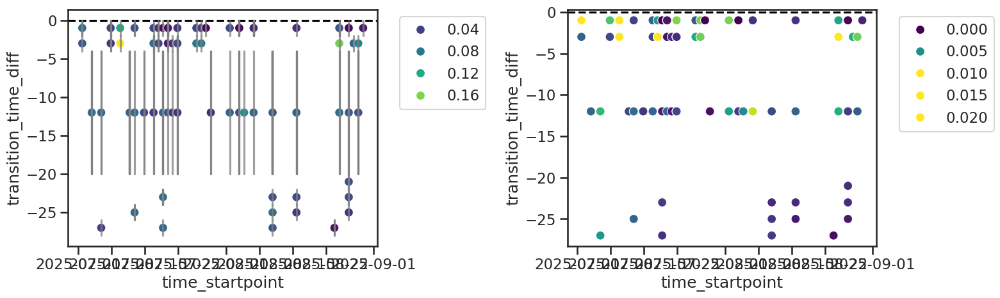

In [141]:
bt_tmp = bt_co_forward_from_c
fig, axs = plt.subplots(1,2, figsize=(16,5))
sns.scatterplot(ax=axs[0], data = bt_tmp, x='time_startpoint', y='transition_time_diff', hue='lwp', palette='viridis', legend=True, s=100)
sns.scatterplot(ax=axs[1], data = bt_tmp, x='time_startpoint', y='transition_time_diff', hue='rwp', palette='viridis', hue_norm=(1e-6,1e-2), legend=True, s=100)

# add whiskers for uncertainty
for ax in axs:
    for i in range(len(bt_tmp.time_startpoint)):
        if not pd.isna(bt_tmp.transition_time_diff.values[i]):
            axs[0].plot([bt_tmp.time_startpoint.values[i], bt_tmp.time_startpoint.values[i]], 
                    [bt_tmp.transition_time_diff.values[i] - bt_tmp.transition_uncertainty.values[i],
                    bt_tmp.transition_time_diff.values[i] + bt_tmp.transition_uncertainty.values[i]], 
                    color='gray', alpha=0.5)
    ax.axhline(0, color='black', linestyle='--')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
fig.tight_layout()

(-42.0, 42.0)

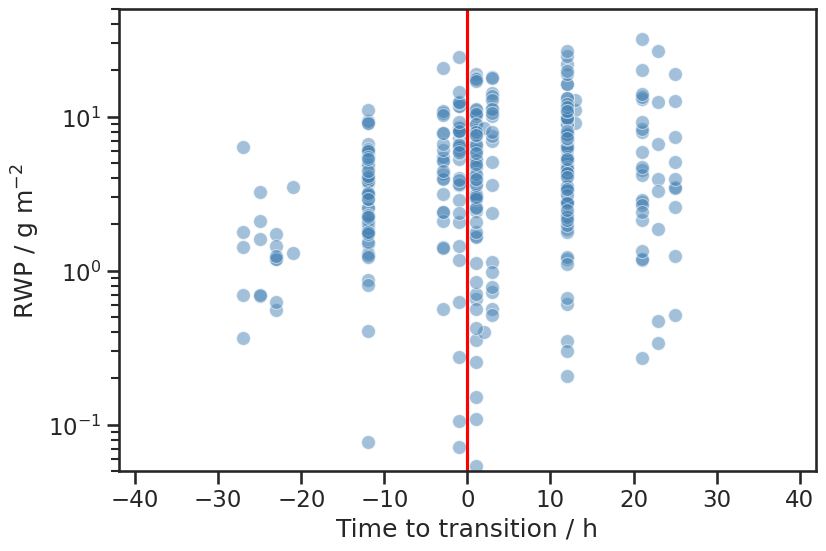

In [142]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

plt.figure(figsize=(9, 6))
sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y=bt_co_forward_from_c['rwp_given_cloud']*1e3, color='steelblue', alpha=0.5, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y=bt_co_back_from_o['rwp_given_cloud']*1e3, color='steelblue', alpha=0.5, s=100)
plt.yscale('log')
plt.ylim(5e-2, 5e1)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')
#median_non_transitioning_clouds = bt_co_forward_from_c.rwp.where(np.isnan(bt_co_forward_from_c.transition_time_diff)).median().values
#plt.axhline(median_non_transitioning_clouds, color='black', linestyle=':', label='Median RWP non-transitioning clouds')
#mean_rwp_closed_cells = acmcap[(acmcap.cats_0 == 1) & (acmcap.cats_1 == 1)].rwp.mean()
#plt.axhline(mean_rwp_closed_cells, color='black', linestyle=':', label='Mean RWP closed-cell clouds (CATS=1)')

# add uncertainty bars for the time to transition
#for bt_tmp in [bt_co_forward_from_c, bt_co_back_from_o]:
#    for i in range(len(bt_tmp.time_startpoint)):
#        if not pd.isna(bt_tmp.transition_time_diff.values[i]):
#            plt.plot( 
#                    [bt_tmp.transition_time_diff.values[i] - bt_tmp.transition_uncertainty.values[i],
#                    bt_tmp.transition_time_diff.values[i] + bt_tmp.transition_uncertainty.values[i]], 
#                    [bt_tmp.rwp_given_cloud.values[i]*1e3, bt_tmp.rwp_given_cloud.values[i]*1e3],
#                    color='gray', alpha=0.3)
plt.xlim(-42, 42)

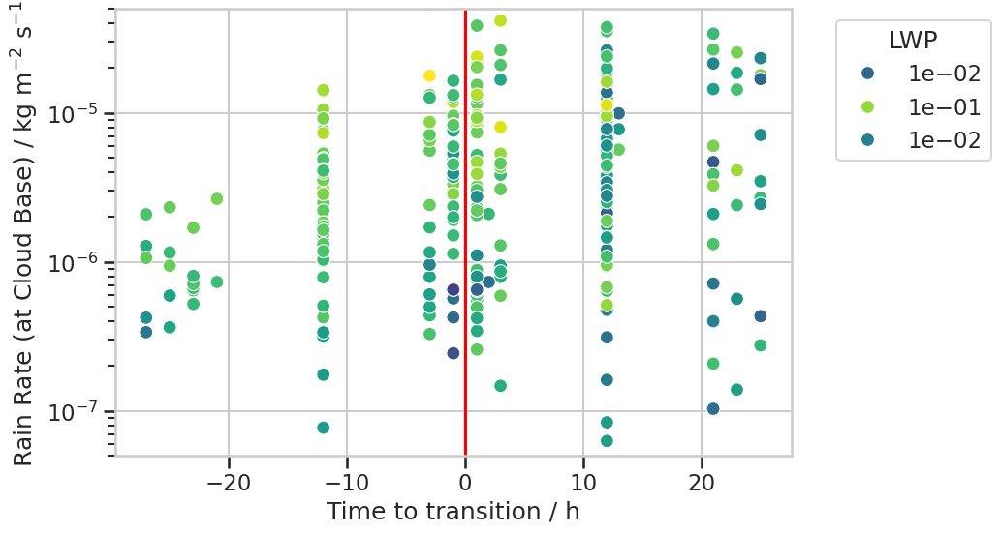

In [143]:
sns.set_context('talk', font_scale=1.)
sns.set_style('whitegrid')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

plt.figure(figsize=(9, 6))
sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
plt.yscale('log')
plt.ylim(5e-8, 5e-5)
plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left', )
plt.xlabel('Time to transition / h')
plt.ylabel('Rain Rate (at Cloud Base) / kg m$^{-2}$ s$^{-1}$')
plt.axvline(0, color='red', linestyle='-')

# add uncertainty bars for the time to transition
#for bt_tmp in [bt_co_forward_from_c, bt_co_back_from_o]:
#    for i in range(len(bt_tmp.time_startpoint)):
#        if not pd.isna(bt_tmp.transition_time_diff.values[i]):
#            plt.plot( 
#                    [bt_tmp.transition_time_diff.values[i] - bt_tmp.transition_uncertainty.values[i],
#                    bt_tmp.transition_time_diff.values[i] + bt_tmp.transition_uncertainty.values[i]], 
#                    [bt_tmp.rain_rate_cbh.values[i], bt_tmp.rain_rate_cbh.values[i]],
#                    color='gray', alpha=0.3)

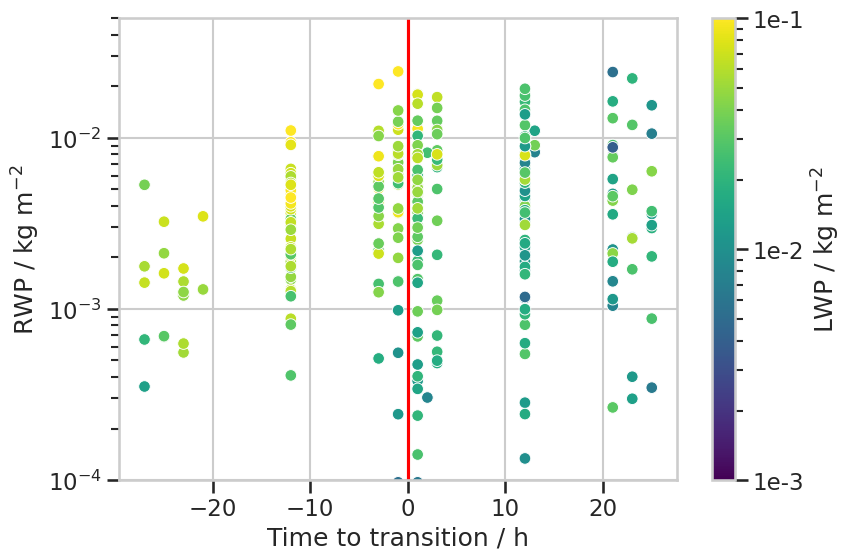

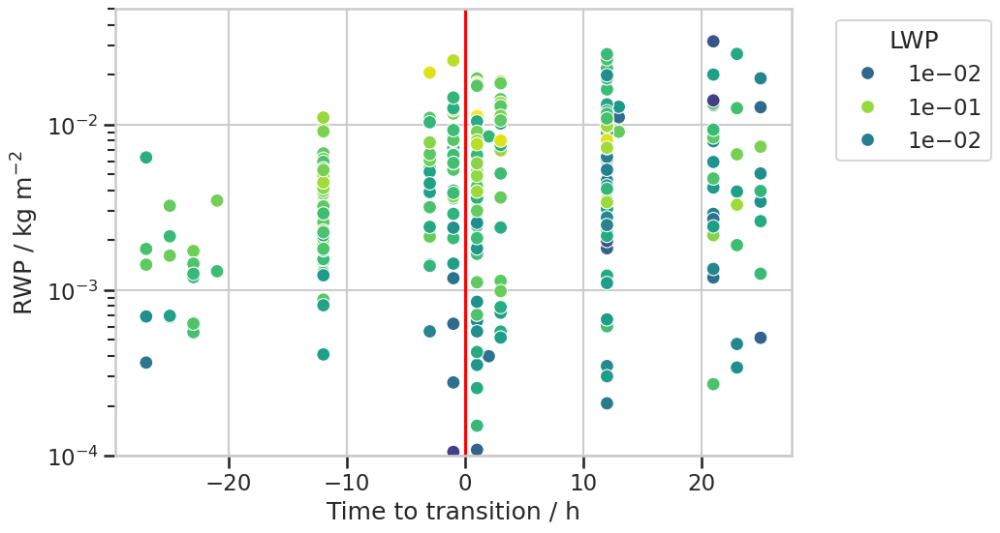

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='rwp', hue='lwp', hue_norm=LogNorm(vmin=1e-3, vmax=1e-1), palette='viridis', legend=False, s=70)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='rwp', hue='lwp', hue_norm=LogNorm(vmin=1e-3, vmax=1e-1), palette='viridis', legend=False, s=70)
plt.yscale('log')
plt.ylim(1e-4, 5e-2)
# Force colorbar with specific ticks
sm = plt.cm.ScalarMappable(cmap='viridis', norm=LogNorm(vmin=1e-3, vmax=1e-1))
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label('LWP / kg m$^{-2}$')
cbar.set_ticks([1e-3, 1e-2, 1e-1])
cbar.set_ticklabels(['1e-3', '1e-2', '1e-1'])

plt.xlabel('Time to transition / h')
plt.ylabel('RWP / kg m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')

# --------------------------------------------
plt.figure(figsize=(9, 6))
sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='rwp_given_cloud', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='rwp_given_cloud', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
plt.yscale('log')
plt.ylim(1e-4, 5e-2)
plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left', )
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / kg m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')


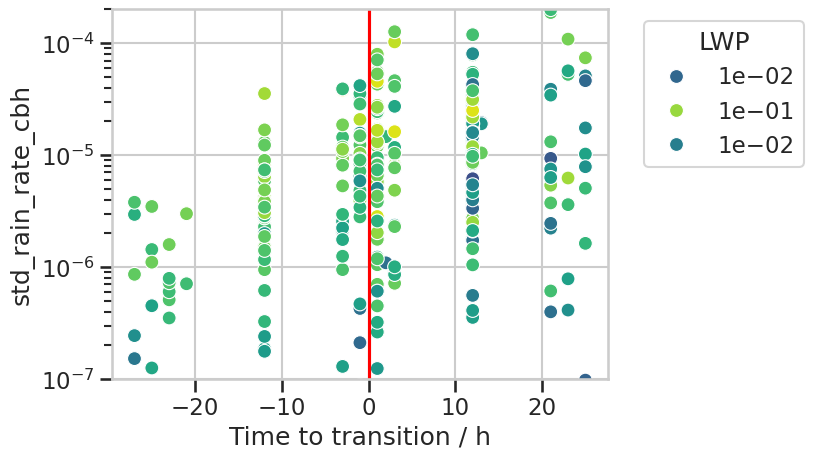

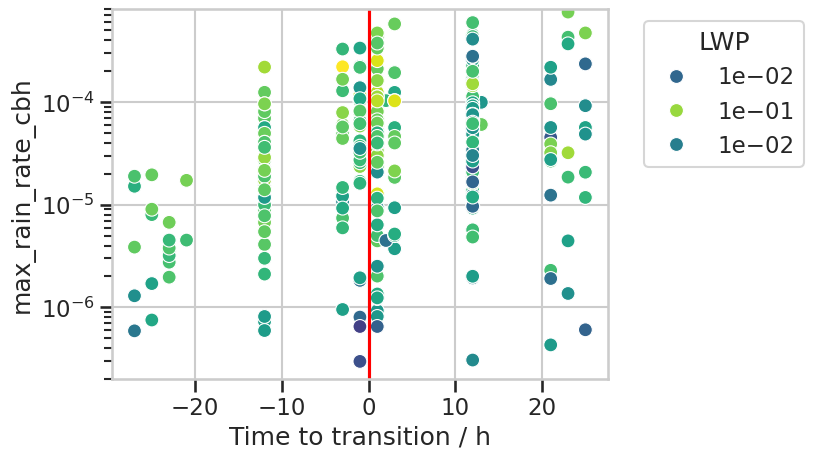

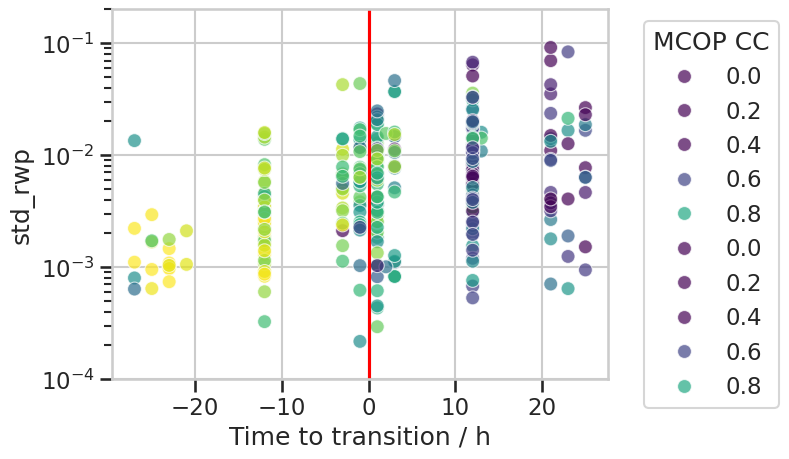

In [145]:
sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='std_rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='std_rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
plt.yscale('log')
plt.ylim(1e-7, 2e-4)
plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='max_rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='max_rain_rate_cbh', hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
plt.yscale('log')
plt.ylim(2e-7, 8e-4)
plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

sns.scatterplot(data = bt_co_forward_from_c, x='transition_time_diff', y='std_rwp', hue='mcop_cc', hue_norm=(0.5, 1), palette='viridis', alpha=0.7, legend=True, s=100)
sns.scatterplot(data = bt_co_back_from_o, x='transition_time_diff', y='std_rwp', hue='mcop_cc', hue_norm=(0.5, 1), palette='viridis', alpha=0.7,legend=True, s=100)
plt.yscale('log')
plt.ylim(1e-4, 2e-1)
plt.legend(title='MCOP CC', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.axvline(0, color='red', linestyle='-')
plt.xlabel('Time to transition / h')
plt.show()

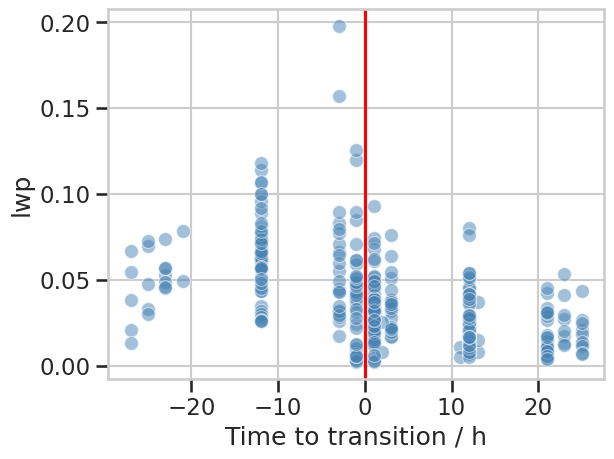

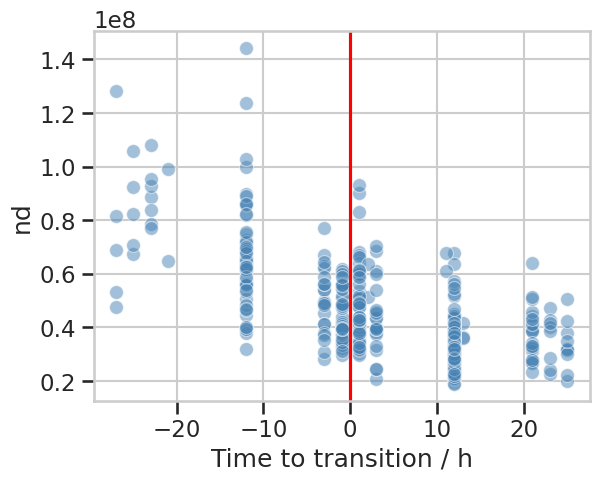

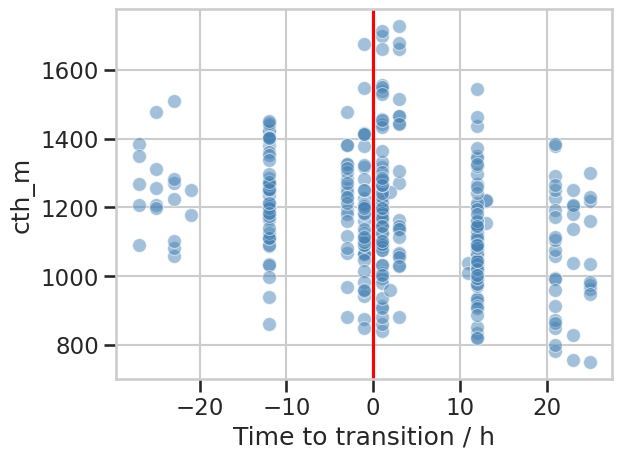

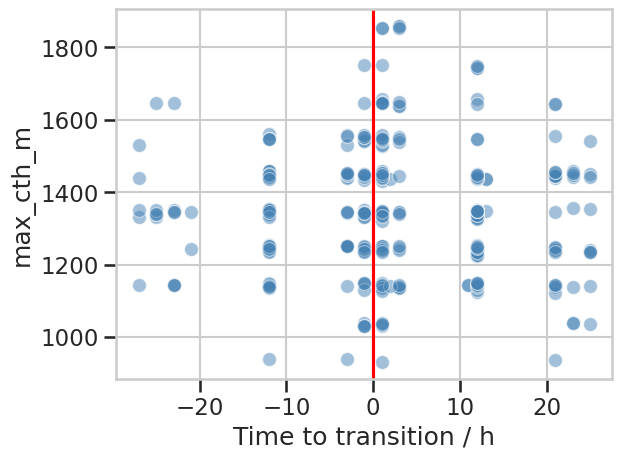

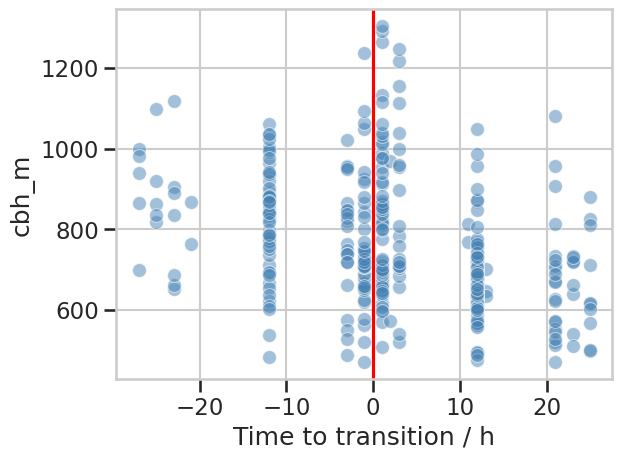

...

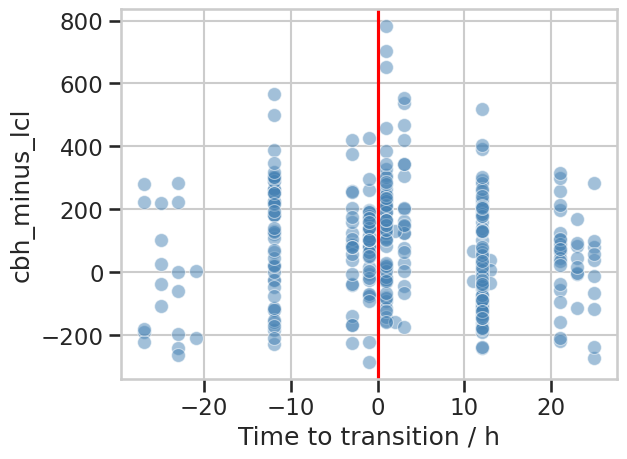

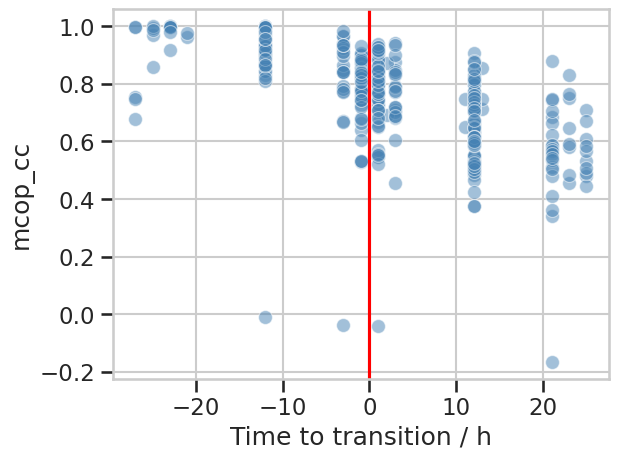

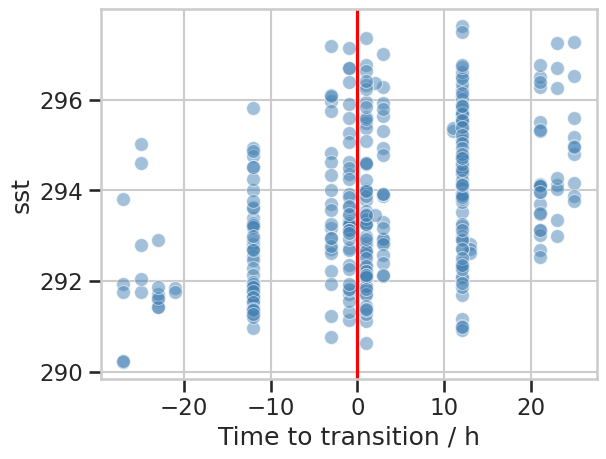

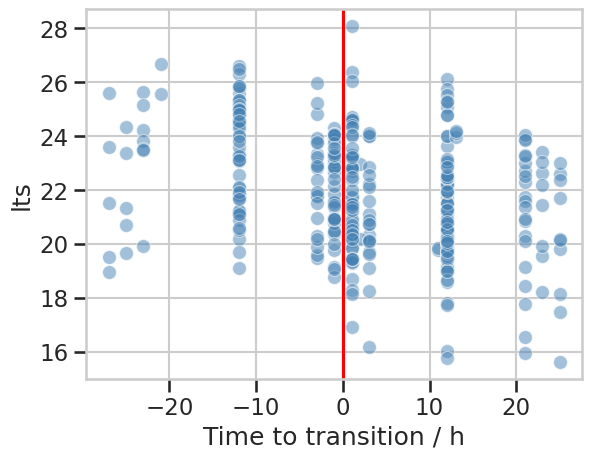

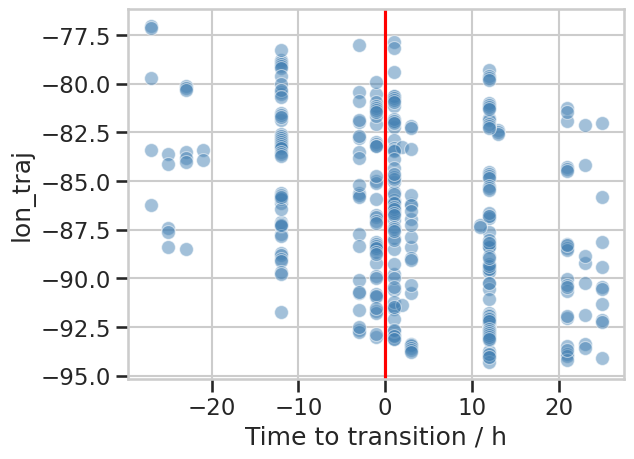

In [159]:
for var in ['lwp', 'nd', 'cth_m', 'max_cth_m', 'cbh_m', 'H', 'cbh_minus_lcl', 'mcop_cc', 'sst', 'lts', 'lon_traj']:
    #sns.scatterplot(data = bt_co_forward_from_c.sel(timestep = 0), x='transition_time_diff', y=var, hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
    #sns.scatterplot(data = bt_co_back_from_o.sel(timestep = 0), x='transition_time_diff', y=var, hue='lwp', hue_norm=LogNorm(), palette='viridis', legend=True, s=100)
    #plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')

    sns.scatterplot(data = bt_co_forward_from_c.sel(timestep = 0), x='transition_time_diff', y=var, legend=False, color='steelblue', alpha=0.5, s=100)
    sns.scatterplot(data = bt_co_back_from_o.sel(timestep = 0), x='transition_time_diff', y=var, legend=False, color='steelblue', alpha=0.5, s=100)
    plt.axvline(0, color='red', linestyle='-')
    plt.xlabel('Time to transition / h')
    plt.show()

In [147]:
bt_co_concat = xr.concat([bt_co_forward_from_c.sel(timestep = 0), bt_co_back_from_o.sel(timestep = 0)], dim='time_startpoint')

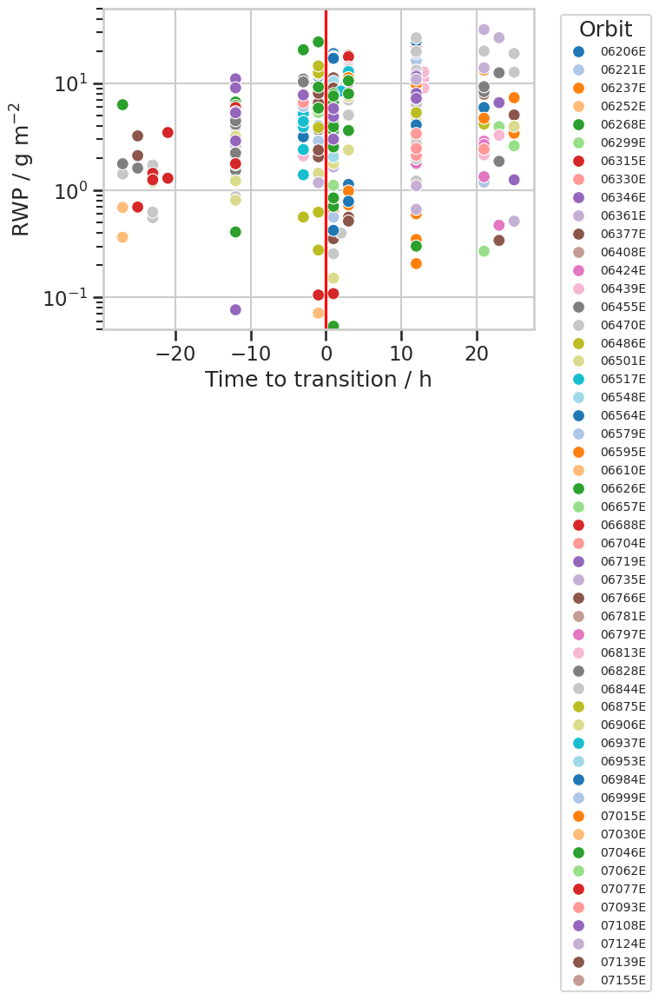

In [ ]:
sns.scatterplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp_given_cloud']*1e3, hue='orbit', palette='tab20', legend=True, s=100)
plt.yscale('log')
plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.ylim(5e-2, 5e1)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')

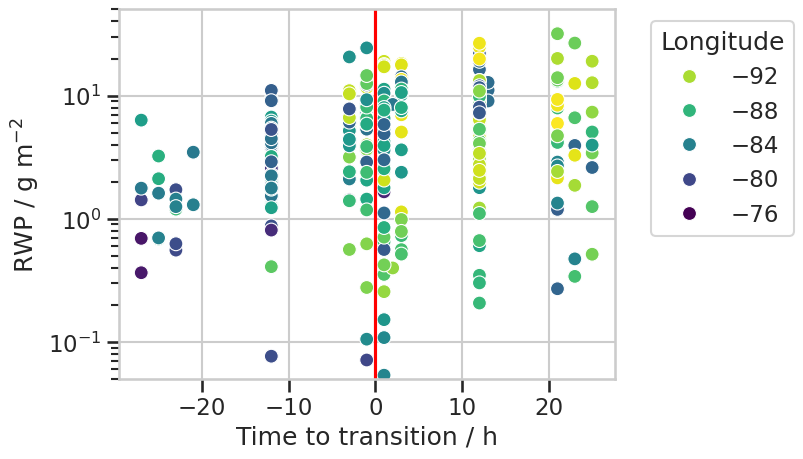

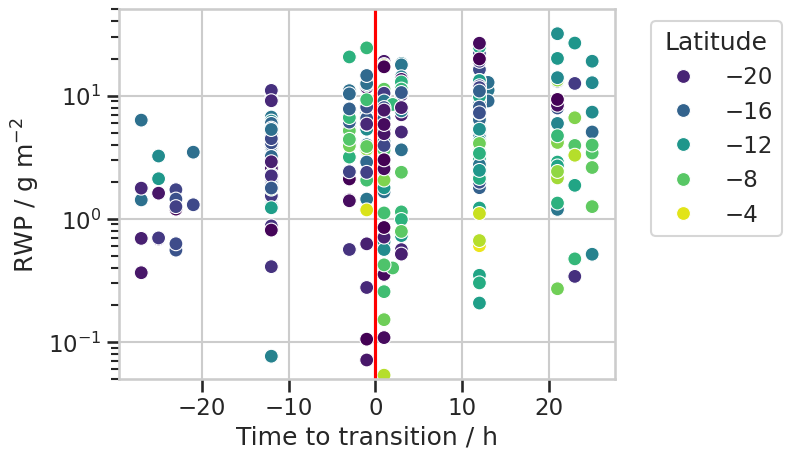

In [152]:
from matplotlib.colors import LogNorm
sns.scatterplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp_given_cloud']*1e3, hue='lon_traj', palette='viridis_r', legend=True, s=100)
plt.yscale('log')
plt.legend(title='Longitude', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylim(5e-2, 5e1)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')
plt.show()

sns.scatterplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp_given_cloud']*1e3, hue='lat_traj', palette='viridis', legend=True, s=100)
plt.yscale('log')
plt.legend(title='Latitude', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylim(5e-2, 5e1)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')

/tmp/ipykernel_3939684/1193837884.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


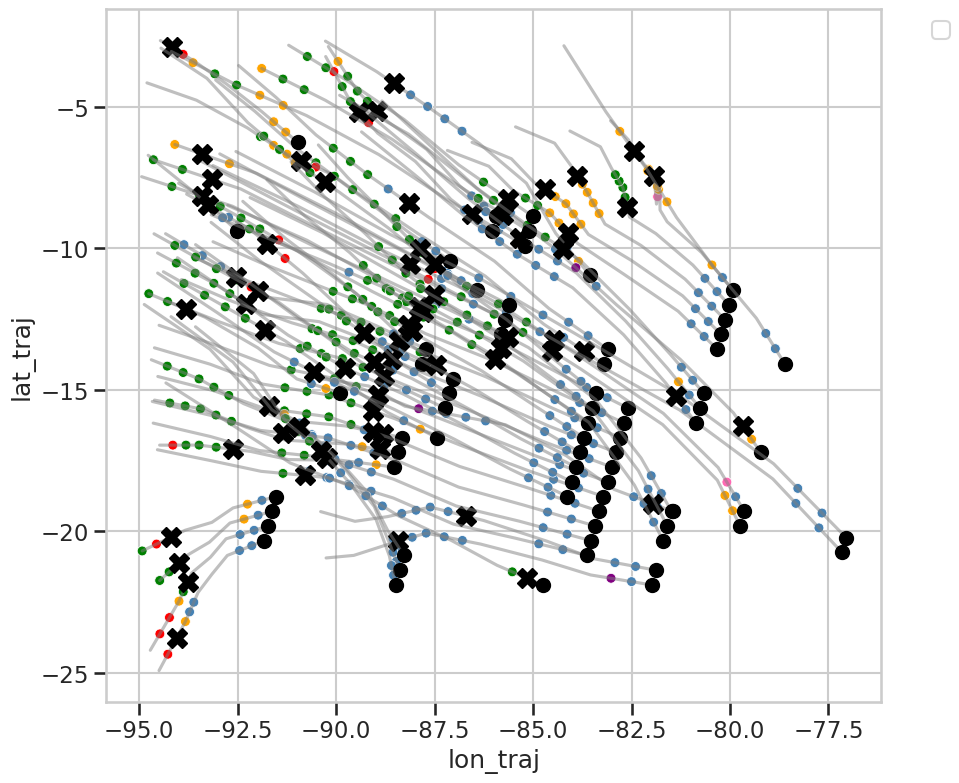

/tmp/ipykernel_3939684/1193837884.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


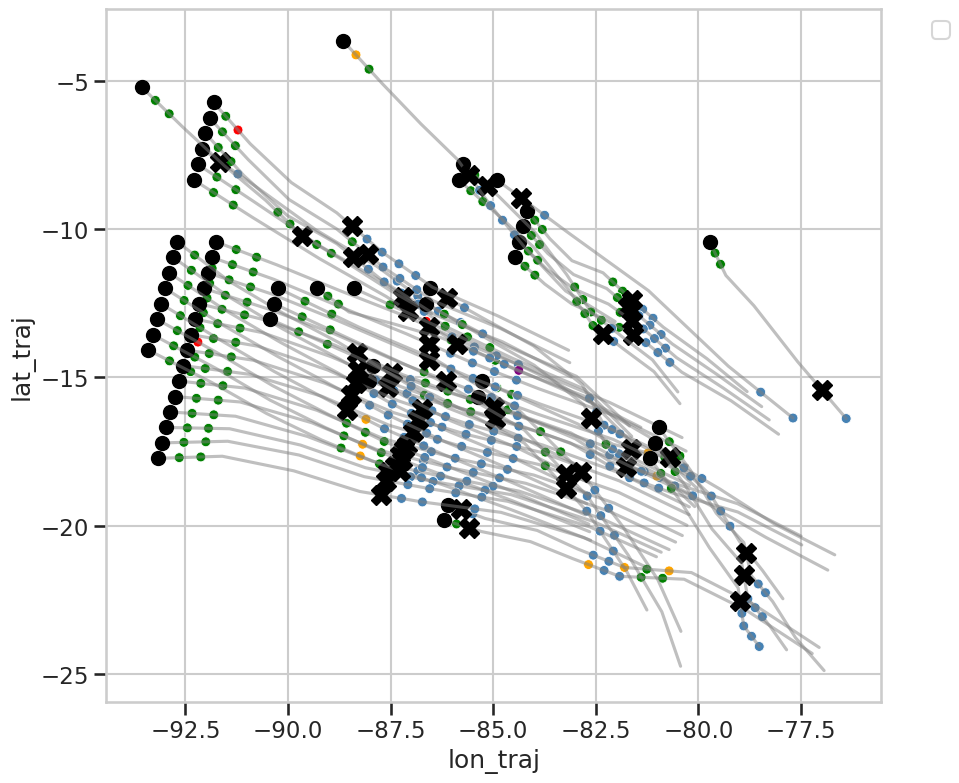

In [ ]:

plt.figure(figsize=(10, 9))
bt_co_forward_from_c_with_trans = bt_co_forward_from_c.where(~ np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True)
for startpoint in bt_co_forward_from_c_with_trans.time_startpoint.values:
    tmp = bt_co_forward_from_c_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(0,50)).sortby('timestep')
    orbit = tmp.orbit_startpoint.values
    sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=10)
    transition_timestep = tmp.transition_timestep.values
    plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=15, color='black')
    sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=50, marker='o')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

plt.figure(figsize=(10, 9))
bt_co_back_from_o_with_trans = bt_co_back_from_o.where(~ np.isnan(bt_co_back_from_o.transition_time_diff) & ~np.isnan(bt_co_back_from_o.lwp), drop=True)
for startpoint in bt_co_back_from_o_with_trans.time_startpoint.values:
    tmp = bt_co_back_from_o_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(-50,1)).sortby('timestep')
    orbit = tmp.orbit_startpoint.values
    sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=10)
    transition_timestep = tmp.transition_timestep.values
    plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=15, color='black')
    sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=50, marker='o')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

#### compare CO clouds with non-transitioning clouds

In [29]:
bt_cc_forward_from_c = add_acmcap_info_to_bt(bt_cc_forward_from_c, acmcap, transition_from_msi_cats=[0,1])
bt_cc_forward_from_c = bt_cc_forward_from_c.where(bt_cc_forward_from_c.cats_startpoint.isin([0,1]), drop=True)

2025-08-01T19:20:13.001890432
CATS_0 = [0, 1] match confirmed
2025-08-01T19:20:21.065958016
No CATS = [0, 1] match found
2025-08-01T19:20:29.130020928
No CATS = [0, 1] match found
2025-08-01T19:20:37.194084992
CATS_0 = [0, 1] match confirmed
2025-08-01T19:20:45.258147968
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:20:53.322211968
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:01.386274944
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:09.450338944
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:33.642530048
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:49.770657024
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:21:57.834720448
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-08-01T19:22:05.898784000
CATS_0 = [0, 1] match confirmed
CATS_1 = [0, 1] match confirmed
2025-0

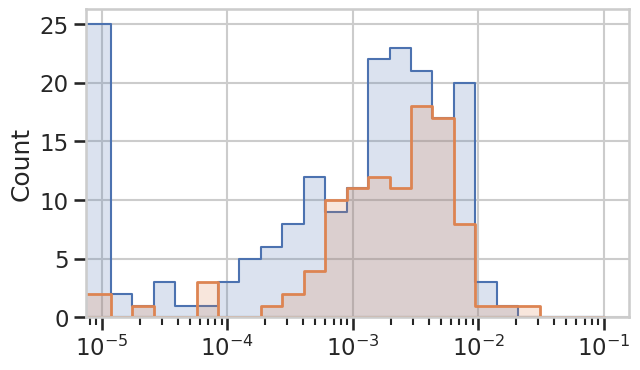

In [30]:
bins = np.logspace(-5.1, -1, 25)
bins[0] = 0
plt.figure(figsize=(7, 4))
sns.histplot(bt_cc_forward_from_c.rwp, bins=bins, alpha=0.2, element='step')

bt_co_forward_from_c_transitioning = bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True)
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

In [31]:
bt_cc_forward_from_c.cats_startpoint

<xarray.DataArray 'cats_startpoint' (time_startpoint: 194)> Size: 2kB
array([0., 0., 0., 0., 0., 1., 1., 1., 1., 0., 1., 1., 1., 1., 1., 1., 1.,
       1., 0., 0., 1., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0.,
       0., 0., 0., 1., 1., 1., 1., 0., 1., 1., 1., 1., 1., 1., 0., 1., 1.,
       1., 1., 1., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 0.,
       0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 1., 1.,
       1., 1., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 1., 1., 1., 1., 1., 0.,
       0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 0., 0., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 1., 1., 1., 1., 1., 1., 0.,
       0., 0., 1., 1., 1., 1., 1., 1., 0., 0., 0., 1., 1., 1., 1., 1., 1.,
       1., 1., 0., 1., 1., 1., 0.])
Coordinates:
  * time_startpoint  (time_startpoint) datetime64[ns] 2kB 2025-08-01T19:20:13...

In [ ]:
bt_cc_forward_from_c['flag_neighboring_transitioning'] = xr.DataArray(np.zeros(len(bt_cc_forward_from_c.time_startpoint), dtype=bool), dims='time_startpoint', coords={'time_startpoint': bt_cc_forward_from_c.time_startpoint.values})
for i in range(len(bt_cc_forward_from_c.time_startpoint)):
    time_diff_to_transitioning_traj = np.abs(bt_cc_forward_from_c.time_startpoint.values[i] - bt_co_forward_from_c_transitioning.time_startpoint.values).min() / np.timedelta64(1, 's')
    if time_diff_to_transitioning_traj <= 15:  # within 15 seconds
        bt_cc_forward_from_c['flag_neighboring_transitioning'].values[i] = True

bt_cc_forward_from_c['flag_non_existing_forward_trajectory'] = (~np.isnan(bt_cc_forward_from_c.sel(timestep=slice(1,42)).goes_cats)).sum(dim='timestep') < 5

bt_cc_forward_from_c['flag_neighboring_open_cells'] = xr.DataArray(np.zeros(len(bt_cc_forward_from_c.time_startpoint), dtype=bool), dims='time_startpoint', coords={'time_startpoint': bt_cc_forward_from_c.time_startpoint.values})
for i in range(len(bt_cc_forward_from_c.time_startpoint)):
    t_ = bt_cc_forward_from_c.time_startpoint.values[i] 
    cats_in_neighborhood = judge_SEP[np.abs(pd.to_datetime(judge_SEP.time_mid) - t_) < pd.Timedelta('10s')]['cats']
    if 2 in cats_in_neighborhood.values:
        bt_cc_forward_from_c['flag_neighboring_open_cells'].values[i] = True

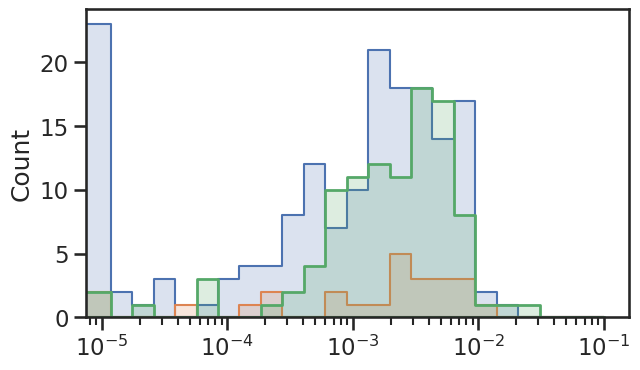

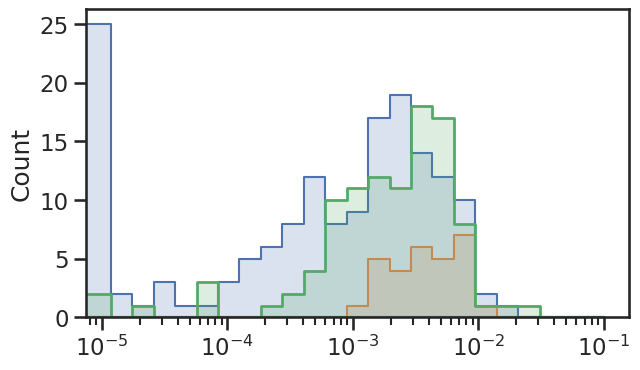

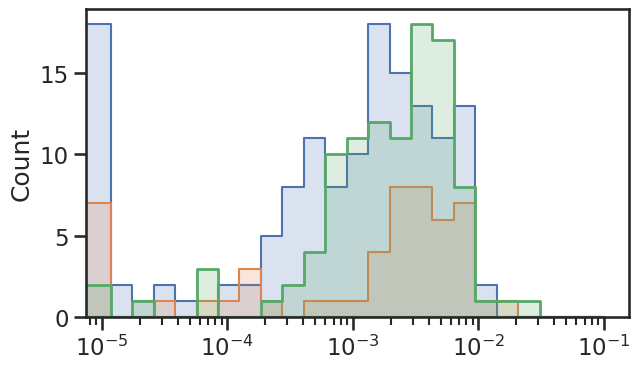

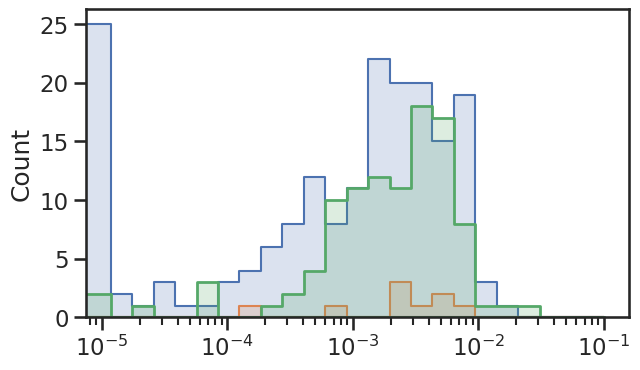

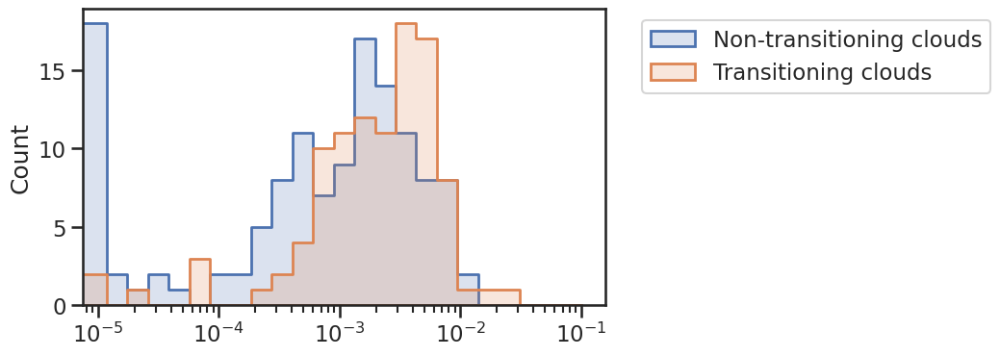

In [61]:
bins = np.logspace(-5.1, -1, 25)
bins[0] = 0

plt.figure(figsize=(7, 4))
#sns.histplot(bt_cc_forward_from_c.rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(~bt_cc_forward_from_c.flag_neighboring_transitioning).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(bt_cc_forward_from_c.flag_neighboring_transitioning).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

plt.figure(figsize=(7, 4))
#sns.histplot(bt_cc_forward_from_c.rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(bt_cc_forward_from_c.lon_traj.sel(timestep=0) > -92).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(bt_cc_forward_from_c.lon_traj.sel(timestep=0) <= -92).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

plt.figure(figsize=(7, 4))
#sns.histplot(bt_cc_forward_from_c.rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(~bt_cc_forward_from_c.flag_non_existing_forward_trajectory).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(bt_cc_forward_from_c.flag_non_existing_forward_trajectory).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

plt.figure(figsize=(7, 4))
#sns.histplot(bt_cc_forward_from_c.rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(~bt_cc_forward_from_c.flag_neighboring_open_cells).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_cc_forward_from_c.where(bt_cc_forward_from_c.flag_neighboring_open_cells).rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

plt.figure(figsize=(7, 4))
bt_cc_forward_from_c_filtered = bt_cc_forward_from_c.where((
                                            #(~bt_cc_forward_from_c.flag_neighboring_transitioning) &
                                            (bt_cc_forward_from_c.lon_traj.sel(timestep=0) > -92) &
                                            (~bt_cc_forward_from_c.flag_non_existing_forward_trajectory) 
                                            #& (~bt_cc_forward_from_c.flag_neighboring_open_cells)
                                                           ))
sns.histplot(bt_cc_forward_from_c_filtered.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Non-transitioning clouds')
sns.histplot(bt_co_forward_from_c_transitioning.rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

In [506]:
bt_cc_forward_from_c_filtered.rwp.median()

<xarray.DataArray 'rwp' ()> Size: 8B
array(0.00090893)

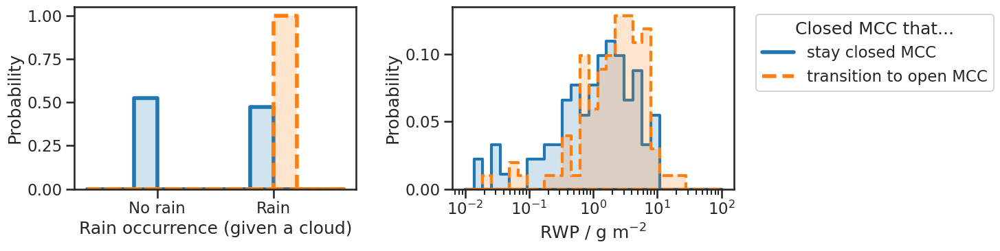

In [34]:
bt_cc_forward_from_c_filtered_0 = bt_cc_forward_from_c.where((
                                            #(~bt_cc_forward_from_c.flag_neighboring_transitioning) &
                                            (bt_cc_forward_from_c.lon_traj.sel(timestep=0) > -90) &
                                            (~bt_cc_forward_from_c.flag_non_existing_forward_trajectory) 
                                            #& (~bt_cc_forward_from_c.flag_neighboring_open_cells)
                                                           ))
bt_cc_forward_from_c_filtered_1 = bt_cc_forward_from_c.where((
                                            (bt_cc_forward_from_c.flag_neighboring_transitioning) &
                                            (bt_cc_forward_from_c.lon_traj.sel(timestep=0) > -92) &
                                            (~bt_cc_forward_from_c.flag_non_existing_forward_trajectory) 
                                            #& (~bt_cc_forward_from_c.flag_neighboring_open_cells)
                                                           ))

line_styles = ['-', '--', '-.']
colors = sns.color_palette('tab10')
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

fig, ax = plt.subplots(1,2, figsize=(11, 4))
for j,dffil in enumerate([bt_cc_forward_from_c_filtered_0, bt_co_forward_from_c_transitioning]): #6
    sns.histplot(ax=ax[0], x=(dffil['rwp_given_cloud'] > 0) + j*0.2, bins=np.arange(-0.5,1.8,0.2), 
                 element='step', alpha=0.2, stat='probability', lw=4, color=colors[j], ls=line_styles[j])
    sns.histplot(
        ax=ax[1], x=dffil['rwp_given_cloud']*1e3, bins=np.logspace(-2,2,30),
        element='step', stat='probability', fill=True, alpha=0.2, lw=3, ls=line_styles[j],
        color=colors[j])


ax[1].set_xscale('log')
ax[1].set_xlabel('RWP / g m$^{-2}$')

ax[0].set_xticks([0.1,1.1])
ax[0].set_xticklabels(['No rain', 'Rain'])
ax[0].set_xlabel('Rain occurrence (given a cloud)')
fig.tight_layout()

legend_handles = [
    plt.Line2D([0], [0], color=colors[0], lw=4, ls=line_styles[0], label='stay closed MCC'),
    plt.Line2D([0], [0], color=colors[1], lw=4, ls=line_styles[1], label='transition to open MCC')
]
ax[1].legend(title='Closed MCC that...', handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left')

In [ ]:
'06844E' # not closed cells but disorg
'06906E' # on the edge of becomming open cell
'06937E' # on the edge of becoming open cell
'07015E' # only few timesteps after EC

'06844E'

In [82]:
# high RWP non-transitioning clouds
bt_cc_forward_from_c_filtered_0.where((bt_cc_forward_from_c_filtered_0.rwp_given_cloud > 5e-3), drop=True)[['rwp_given_cloud', 'orbit_startpoint', 'time_startpoint', 'mcop_cc']].to_dataframe()

,rwp_given_cloud,orbit_startpoint,mcop_cc
time_startpoint,,,
2025-08-06 19:39:57.834131008,0.007888,06766E,0.912750
2025-08-06 19:40:05.898194048,0.006571,06766E,0.884949
2025-08-06 19:42:14.923219008,0.006707,06766E,0.928528
2025-08-06 19:42:22.987286080,0.005336,06766E,0.929077
2025-08-17 19:25:31.347787136,0.010685,06937E,0.844940
2025-08-17 19:25:39.411851136,0.008819,06937E,0.813293
2025-08-22 19:43:45.948557056,0.005356,07015E,0.936890
2025-08-24 19:33:41.622588992,0.007804,07046E,0.923737
2025-08-28 19:13:05.064712960,0.008488,07108E,0.890472


In [402]:
rwp_thresh = 3e-3
n_trans_smaller_thresh = bt_co_forward_from_c_transitioning.where(bt_co_forward_from_c_transitioning.rwp < rwp_thresh, drop=True).rwp.count()
n_trans_greater_thresh = bt_co_forward_from_c_transitioning.where(bt_co_forward_from_c_transitioning.rwp >= rwp_thresh, drop=True).rwp.count()
n_non_trans_smaller_thresh = bt_cc_forward_from_c.where(bt_cc_forward_from_c.rwp < rwp_thresh, drop=True).rwp.count()
n_non_trans_greater_thresh = bt_cc_forward_from_c.where(bt_cc_forward_from_c.rwp >= rwp_thresh, drop=True).rwp.count()

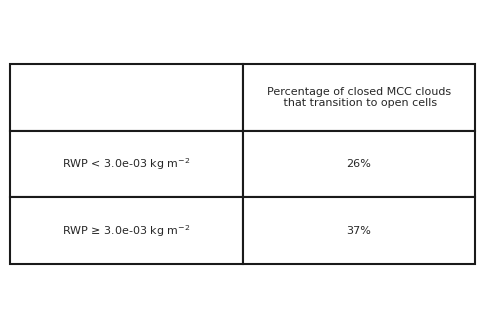

In [403]:
percent_of_transitioning_clouds_for_rwp_smaller_thresh = n_trans_smaller_thresh / (n_trans_smaller_thresh + n_non_trans_smaller_thresh)
percent_of_transitioning_clouds_for_rwp_greater_thresh = n_trans_greater_thresh / (n_trans_greater_thresh + n_non_trans_greater_thresh)

# plot a table
plt.figure(figsize=(6, 4))
table_data = [
    ['RWP < {:.1e} kg m$^{{-2}}$'.format(rwp_thresh), f'{percent_of_transitioning_clouds_for_rwp_smaller_thresh:.0%}'],
    ['RWP ≥ {:.1e} kg m$^{{-2}}$'.format(rwp_thresh), f'{percent_of_transitioning_clouds_for_rwp_greater_thresh:.0%}']
]
columns = ['', 'Percentage of closed MCC clouds\n that transition to open cells']
table = plt.table(cellText=table_data, colLabels=columns, cellLoc='center', loc='center', colWidths=[0.5, 0.5])
plt.axis('off')
table.set_fontsize(12)
table.scale(1, 4)  # Scale width=1, height=2

Text(0.5, 0, 'RWP / kg m$^{-2}$')

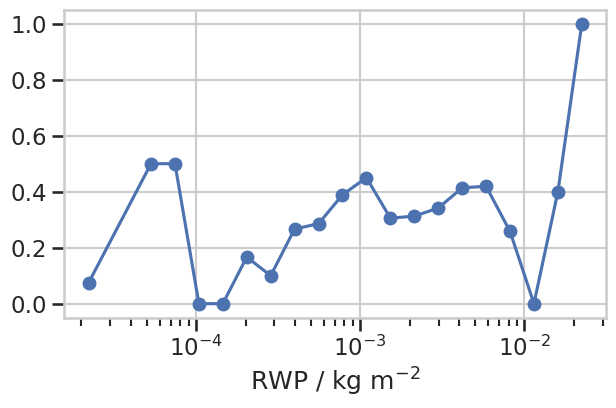

In [404]:
# plot probability that cloud will transition vs RWP
bins = np.logspace(-4.5, -1, 25)
bins[0] = 0
rwp_bin_centers = (bins[:-1] + bins[1:]) / 2
rwp_hist_trans = np.histogram(bt_co_forward_from_c_transitioning.rwp, bins=bins)[0]
rwp_hist_non_trans = np.histogram(bt_cc_forward_from_c.rwp, bins=bins)[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rwp_bin_centers, rwp_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('RWP / kg m$^{-2}$')

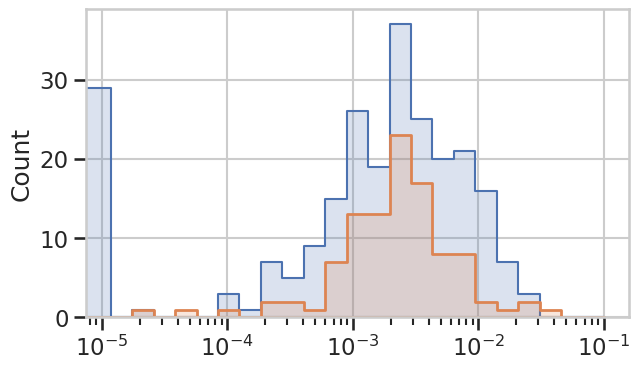

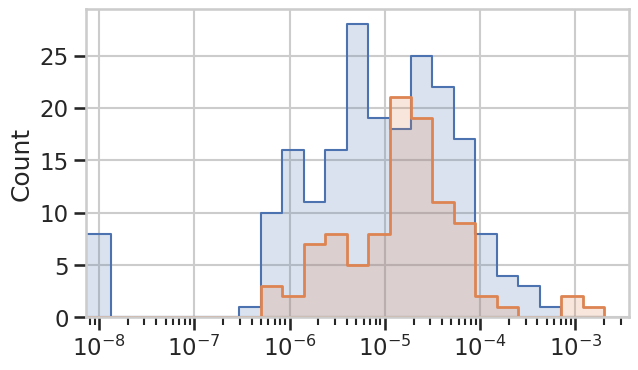

In [408]:
bins = np.logspace(-5.1, -1, 25)
bins[0] = 0
plt.figure(figsize=(7, 4))
sns.histplot(bt_cc_forward_from_c.std_rwp, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.std_rwp, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')

bins = np.logspace(-8.1, -2.7, 25)
bins[0] = 0
plt.figure(figsize=(7, 4))
sns.histplot(bt_cc_forward_from_c.max_rain_rate_cbh, bins=bins, alpha=0.2, element='step')
sns.histplot(bt_co_forward_from_c_transitioning.max_rain_rate_cbh, bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
plt.xscale('log')
plt.show()

---
using all ACMCAP data (but maybe this is unnecessarily complicated): 

In [ ]:
variables = ['rwp', 'orbit', 'time', 'stratus_region_index', 'latitude', 'longitude']

# handle the overlapping scene classification
acmcap_0 = acmcap[
    (acmcap.scene_id_0 != -1) &
    (acmcap.ice_flag_0 == 0) &
    (acmcap.cert_0 > 0.75) & 
    (acmcap.MCOP_cloud_cover_judge_0 >= 0.1)
              ][variables + ['cats_0', 'cert_0', 'ice_flag_0', 'scene_id_0', 'MCOP_cloud_cover_judge_0']]
acmcap_1 = acmcap[
    (acmcap.scene_id_1 != -1) &
    (acmcap.ice_flag_1 == 0) &
    (acmcap.cert_1 > 0.75) & 
    (acmcap.MCOP_cloud_cover_judge_1 >= 0.1)
              ][variables + ['cats_1', 'cert_1', 'ice_flag_1', 'scene_id_1', 'MCOP_cloud_cover_judge_1']]
acmcap_0.rename(columns={col: col.replace('_0','') for col in acmcap_0.columns if col.endswith('_0') and col != 'scene_id_0'}, inplace=True)
acmcap_1.rename(columns={col: col.replace('_1','') for col in acmcap_1.columns if col.endswith('_1') and col != 'scene_id_1'}, inplace=True)
acmcap_tmp = pd.concat([acmcap_0, acmcap_1], axis=0, ignore_index=True)
acmcap_tmp['scene_id'] = np.where(~np.isnan(acmcap_tmp.scene_id_0), acmcap_tmp.scene_id_0, acmcap_tmp.scene_id_1 + acmcap_tmp.scene_id_0.max() + acmcap_tmp.scene_id_1.min())

# only use scenes in August 2025, in stratus region 2, and closed-cell scenes (cats == 1)
acmcap_tmp = acmcap_tmp[(
    ((pd.to_datetime(acmcap_tmp['time']) >= pd.to_datetime('2025-08-01')) 
    & (acmcap_tmp.stratus_region_index == 2) 
    & (acmcap_tmp.cats.isin([0,1]))
    & (acmcap_tmp.longitude >= -92)  # if clouds are too close to longitude boundary we can not see transitions
    ) 
    #| ((acmcap_tmp.stratus_region_index == 0) & (acmcap_tmp.cats.isin([0,1])))
)]
acmcap_per_scene = acmcap_tmp.groupby(['orbit', 'scene_id']).mean()
acmcap_per_scene['max_rwp'] = acmcap_tmp.groupby(['orbit', 'scene_id']).max()['rwp']
acmcap_per_scene['std_rwp'] = acmcap_tmp.groupby(['orbit', 'scene_id']).std()['rwp']
acmcap_per_scene['inhomog_rwp'] = acmcap_per_scene['std_rwp'] / acmcap_per_scene['rwp']

In [ ]:
co_from_c_scene_id_0 = np.unique(bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1])), drop=True).scene_id_0.values)
co_from_c_scene_id_1 = np.unique(bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1])), drop=True).scene_id_1.values)
co_from_c_time = np.unique(bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1])), drop=True).time_startpoint.values)

co_from_c_15h_scene_id_0 = np.unique(bt_co_forward_from_c.where((bt_co_forward_from_c.transition_time_diff > -15) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1])), drop=True).scene_id_0.values)
co_from_c_15h_scene_id_1 = np.unique(bt_co_forward_from_c.where((bt_co_forward_from_c.transition_time_diff > -15) & (bt_co_forward_from_c.cats_startpoint.isin([0, 1])), drop=True).scene_id_1.values)

In [ ]:
# if there is too few timesteps (< 5) after the EC overpass, discard the scene_ids
bt_to_exclude = bt_co_forward_from_c.where((~np.isnan(bt_co_forward_from_c.sel(timestep=slice(1,42)).goes_cats)).sum(dim='timestep') < 5, drop=True)

In [ ]:
non_trans_scene_id_0 = [acmcap_per_scene.scene_id_0.values[i] for i in range(len(acmcap_per_scene.scene_id_0.values)) if (acmcap_per_scene.scene_id_0.values[i] not in list(co_from_c_scene_id_0)) & (~np.isnan(acmcap_per_scene.scene_id_0.values[i]))]
non_trans_scene_id_1 = [acmcap_per_scene.scene_id_1.values[i] for i in range(len(acmcap_per_scene.scene_id_1.values)) if (acmcap_per_scene.scene_id_1.values[i] not in list(co_from_c_scene_id_1)) & (~np.isnan(acmcap_per_scene.scene_id_1.values[i]))]
acmcap_non_trans_scenes = acmcap_per_scene[(acmcap_per_scene.scene_id_0.isin(non_trans_scene_id_0) | acmcap_per_scene.scene_id_1.isin(non_trans_scene_id_1)) & (~acmcap_per_scene.scene_id_0.isin(bt_to_exclude.scene_id_0) & ~acmcap_per_scene.scene_id_1.isin(bt_to_exclude.scene_id_1))]

#neightbor_traj_to_trans_scene_id_0 = [acmcap_per_scene.scene_id_0.values[i] for i in range(len(acmcap_per_scene.scene_id_0.values)) if (np.abs(acmcap_per_scene.time.values[i] - co_from_c_time).min() / np.timedelta64(1, 's') <= 15)]
#neightbor_traj_to_trans_scene_id_1 = [acmcap_per_scene.scene_id_1.values[i] for i in range(len(acmcap_per_scene.scene_id_1.values)) if (np.abs(acmcap_per_scene.time.values[i] - co_from_c_time).min() / np.timedelta64(1, 's') <= 15)]
#acmcap_non_trans_non_neighbor_scenes = acmcap_per_scene[(acmcap_per_scene.scene_id_0.isin(non_trans_scene_id_0) | acmcap_per_scene.scene_id_1.isin(non_trans_scene_id_1)) 
#                                           & (~acmcap_per_scene.scene_id_0.isin(bt_to_exclude.scene_id_0) & ~acmcap_per_scene.scene_id_1.isin(bt_to_exclude.scene_id_1))
#                                           & (~acmcap_per_scene.scene_id_0.isin(neightbor_traj_to_trans_scene_id_0) & ~acmcap_per_scene.scene_id_1.isin(neightbor_traj_to_trans_scene_id_1))]
#acmcap_non_trans_neighbor_scenes = acmcap_per_scene[(acmcap_per_scene.scene_id_0.isin(non_trans_scene_id_0) | acmcap_per_scene.scene_id_1.isin(non_trans_scene_id_1)) 
#                                           & (~acmcap_per_scene.scene_id_0.isin(bt_to_exclude.scene_id_0) & ~acmcap_per_scene.scene_id_1.isin(bt_to_exclude.scene_id_1))
#                                           & (acmcap_per_scene.scene_id_0.isin(neightbor_traj_to_trans_scene_id_0) | acmcap_per_scene.scene_id_1.isin(neightbor_traj_to_trans_scene_id_1))]

acmcap_trans_scenes = acmcap_per_scene[(acmcap_per_scene.scene_id_0.isin(list(co_from_c_scene_id_0)) | acmcap_per_scene.scene_id_1.isin(list(co_from_c_scene_id_1)))]
acmcap_trans_scenes_15h_before_trans = acmcap_per_scene[(acmcap_per_scene.scene_id_0.isin(list(co_from_c_15h_scene_id_0)) | acmcap_per_scene.scene_id_1.isin(list(co_from_c_15h_scene_id_1)))]

([<matplotlib.axis.XTick at 0x7f43ef25b390>,
 [Text(1e-05, 0, '0-1e-5'),
  Text(0.0001, 0, '1e-4'),
  Text(0.001, 0, '1e-3'),
  Text(0.01, 0, '1e-2'),
  Text(0.1, 0, '1e-1')])

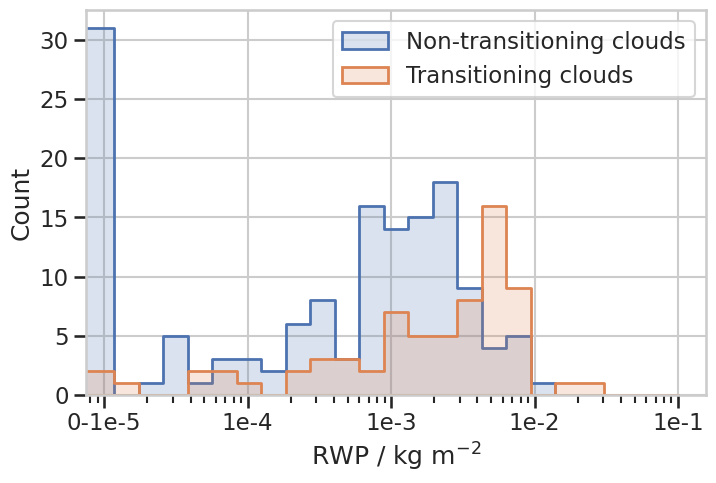

In [ ]:
bins = np.logspace(-5.1, -1, 25)
bins[0] = 0

plt.figure(figsize=(8, 5))
#sns.histplot(data=acmcap_mean, x='rwp', bins=np.logspace(-4.5, -1, 30), alpha=0.2, linewidth=2, element='step')
sns.histplot(acmcap_non_trans_scenes, x='rwp', bins=bins, alpha=0.2, linewidth=2, element='step', label='Non-transitioning clouds')
#sns.histplot(acmcap_non_trans_non_neighbor_scenes, x='rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
#sns.histplot(acmcap_non_trans_neighbor_scenes, x='rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
sns.histplot(acmcap_trans_scenes, x='rwp', bins=bins, alpha=0.2, linewidth=2, element='step', label='Transitioning clouds')
#sns.histplot(acmcap_mean_trans_scenes_15h_before_trans, x='rwp', bins=np.logspace(-4.5, -1, 30), alpha=0.2, linewidth=2, element='step')
plt.legend()
plt.xscale('log')
#plt.yscale('log')
plt.xlabel('RWP / kg m$^{-2}$')
plt.xticks([1e-5, 1e-4, 1e-3, 1e-2, 1e-1], labels=['0-1e-5', '1e-4', '1e-3', '1e-2', '1e-1'])

In [ ]:
rwp_thresh = 3e-3
n_trans_smaller_thresh = acmcap_trans_scenes[acmcap_trans_scenes.rwp < rwp_thresh].rwp.count()
n_trans_greater_thresh = acmcap_trans_scenes[acmcap_trans_scenes.rwp >= rwp_thresh].rwp.count()
n_non_trans_smaller_thresh = acmcap_non_trans_scenes[acmcap_non_trans_scenes.rwp < rwp_thresh].rwp.count()
n_non_trans_greater_thresh = acmcap_non_trans_scenes[acmcap_non_trans_scenes.rwp >= rwp_thresh].rwp.count()

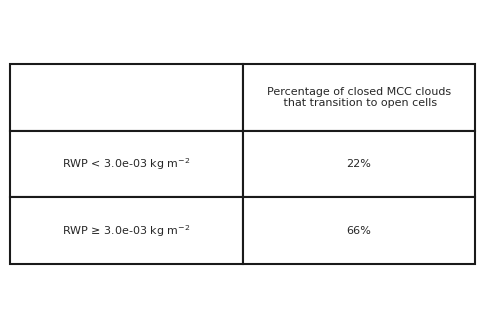

In [ ]:
percent_of_transitioning_clouds_for_rwp_smaller_thresh = n_trans_smaller_thresh / (n_trans_smaller_thresh + n_non_trans_smaller_thresh)
percent_of_transitioning_clouds_for_rwp_greater_thresh = n_trans_greater_thresh / (n_trans_greater_thresh + n_non_trans_greater_thresh)

# plot a table
plt.figure(figsize=(6, 4))
table_data = [
    ['RWP < {:.1e} kg m$^{{-2}}$'.format(rwp_thresh), f'{percent_of_transitioning_clouds_for_rwp_smaller_thresh:.0%}'],
    ['RWP ≥ {:.1e} kg m$^{{-2}}$'.format(rwp_thresh), f'{percent_of_transitioning_clouds_for_rwp_greater_thresh:.0%}']
]
columns = ['', 'Percentage of closed MCC clouds\n that transition to open cells']
table = plt.table(cellText=table_data, colLabels=columns, cellLoc='center', loc='center', colWidths=[0.5, 0.5])
plt.axis('off')
table.set_fontsize(12)
table.scale(1, 4)  # Scale width=1, height=2

Text(0.5, 0, 'RWP / kg m$^{-2}$')

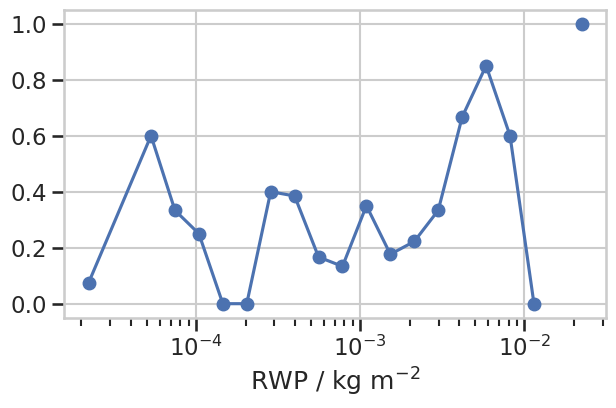

In [ ]:
# plot probability that cloud will transition vs RWP
bins = np.logspace(-4.5, -1, 25)
bins[0] = 0
rwp_bin_centers = (bins[:-1] + bins[1:]) / 2
rwp_hist_trans = np.histogram(acmcap_trans_scenes.rwp, bins=bins)[0]
rwp_hist_non_trans = np.histogram(acmcap_non_trans_scenes.rwp, bins=bins)[0]
rwp_hist_total = rwp_hist_trans + rwp_hist_non_trans
rwp_transition_prob = rwp_hist_trans / rwp_hist_total
plt.figure(figsize=(7, 4))
plt.plot(rwp_bin_centers, rwp_transition_prob, marker='o')
plt.xscale('log')
plt.xlabel('RWP / kg m$^{-2}$')

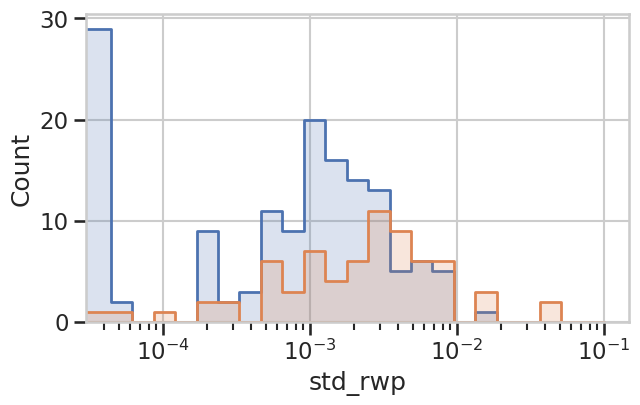

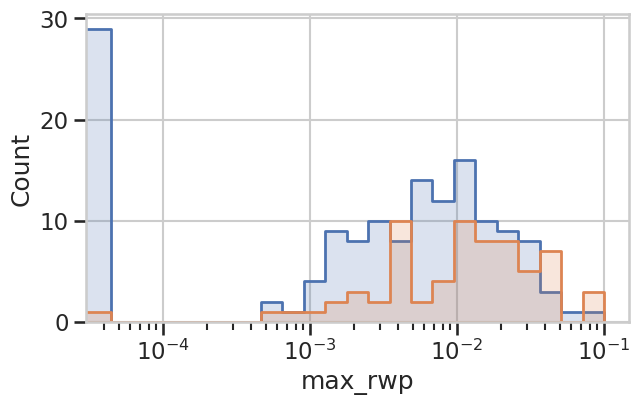

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(acmcap_non_trans_scenes, x='std_rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
sns.histplot(acmcap_trans_scenes, x='std_rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
plt.xscale('log')
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(acmcap_non_trans_scenes, x='max_rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
sns.histplot(acmcap_trans_scenes, x='max_rwp', bins=bins, alpha=0.2, linewidth=2, element='step')
plt.xscale('log')
plt.show()

In [ ]:
acmcap_non_trans_scenes[acmcap_non_trans_scenes.rwp > 4e-3]

rwp                          time  stratus_region_index  \
orbit  scene_id                                                                 
06766E 6250.0    0.008094 2025-08-06 19:39:57.009383168                   2.0   
       14849.0   0.007275 2025-08-06 19:40:05.009664768                   2.0   
06906E 6468.0    0.005552 2025-08-15 19:38:30.397530624                   2.0   
07015E 6616.0    0.004509 2025-08-22 19:42:56.616665088                   2.0   
07030E 6655.0    0.005970 2025-08-23 18:54:26.420296192                   2.0   
07046E 6685.0    0.004227 2025-08-24 19:34:13.032254720                   2.0   
07108E 6783.0    0.007177 2025-08-28 19:10:39.000881664                   2.0   
       15380.0   0.007838 2025-08-28 19:10:31.000596736                   2.0   
       15400.0   0.011019 2025-08-28 19:13:12.221208832                   2.0   
07155E 6888.0    0.006407 2025-08-31 19:39:54.547473664                   2.0   
       15485.0   0.004662 2025-08-31 19:39:46.475539456                   2.0   

                  latitude  longitude  cats      cert  ice_flag  scene_id_0  \
orbit  scene_id                                                               
06766E 6250.0    -8.297562 -86.902600   1.0  0.999479       0.0      6250.0   
       14849.0   -8.815333 -87.000709   1.0  0.999453       0.0         NaN   
06906E 6468.0   -16.641816 -87.628643   1.0  0.855254       0.0      6468.0   
07015E 6616.0    -5.159353 -87.284779   1.0  0.972031       0.0      6616.0   
07030E 6655.0   -18.091561 -76.819246   1.0  0.979732       0.0      6655.0   
07046E 6685.0   -14.554765 -86.293550   1.0  0.906895       0.0      6685.0   
07108E 6783.0    -9.337134 -79.737531   0.0  0.895437       0.0      6783.0   
       15380.0   -8.819410 -79.639043   0.0  0.918662       0.0         NaN   
       15400.0  -19.242447 -81.672351   1.0  0.994667       0.0         NaN   
07155E 6888.0    -8.294692 -86.925218   1.0  0.839952       0.0      6888.0   
       15485.0   -7.772162 -86.826442   1.0  0.857917       0.0         NaN   

                 MCOP_cloud_cover_judge  scene_id_1   max_rwp   std_rwp  \
orbit  scene_id                                                           
06766E 6250.0                  0.946960         NaN  0.031703  0.007576   
       14849.0                 0.878540      6251.0  0.031703  0.007435   
06906E 6468.0                  0.827393         NaN  0.021904  0.005039   
07015E 6616.0                  0.984314         NaN  0.033879  0.005987   
07030E 6655.0                  0.850769         NaN  0.024780  0.006289   
07046E 6685.0                  0.846741         NaN  0.037469  0.006444   
07108E 6783.0                  0.978149         NaN  0.040749  0.007634   
       15380.0                 0.956543      6782.0  0.040749  0.007488   
       15400.0                 0.962341      6802.0  0.084557  0.015587   
07155E 6888.0                  0.990784         NaN  0.027170  0.006083   
       15485.0                 0.931885      6887.0  0.027170  0.006763   

                 inhomog_rwp  
orbit  scene_id               
06766E 6250.0       0.936027  
       14849.0      1.022069  
06906E 6468.0       0.907530  
07015E 6616.0       1.327759  
07030E 6655.0       1.053405  
07046E 6685.0       1.524578  
07108E 6783.0       1.063572  
       15380.0      0.955386  
       15400.0      1.414560  
07155E 6888.0       0.949495  
       15485.0      1.450693

#### ACMCAP frames for CO transitions

In [23]:
sys.path.append('./../../../ectools/')
from ectools import ecio
from ectools import ecplot as ecplt

In [ ]:
bt_co_c = bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True)
bt_co_o = bt_co_back_from_o.where(~np.isnan(bt_co_back_from_o.transition_time_diff), drop=True)

orbits_c = np.unique(bt_co_c.orbit_startpoint)
orbits_o = np.unique(bt_co_o.orbit_startpoint)
orbits = np.unique(np.concatenate((orbits_c, orbits_o)))
#orbit = orbits[0]
month = '08'

for orbit in orbits: # ['06766E']: '06704E'
    print(f'Plotting orbit {orbit}')

    bt_co_c_orbit = bt_co_c.where(bt_co_c.orbit_startpoint == orbit, drop=True)
    bt_co_o_orbit = bt_co_o.where(bt_co_o.orbit_startpoint == orbit, drop=True)

    # load ACMCAP
    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/{month}/*/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
    lat_range = (-22.5, -2.5)
    lon_range = (-95, -75)
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_range[0]) & (ACMCAP.latitude < lat_range[1]) & (ACMCAP.longitude > lon_range[0]) & (ACMCAP.longitude < lon_range[1]), drop=True)
    ACMCAP.encoding = encoding.copy()

    # load MCOP
    try:
        filename = glob.glob(f'/home/jmayer/Object_Data/MSI_COP_2A/2025/{month}/*/*_{orbit}.h5')[0]
        MCOP = ecio.load_MCOP(filename)
        MCOP = MCOP.assign_coords(
            {
            'along_track': (
                ["along_track"],
                MCOP['along_track'].data,
                MCOP['along_track'].attrs
                ),
            'across_track': (
                ['across_track'],
                MCOP['across_track'].data,
                MCOP['across_track'].attrs
                )
            })
        MCOP2 = MCOP.where((MCOP.latitude > lat_range[0]) & (MCOP.latitude < lat_range[1]) & (MCOP.longitude > lon_range[0]) & (MCOP.longitude < lon_range[1]), drop=True)
        MCOP2 = MCOP2[['latitude','longitude','cloud_water_path','cloud_optical_thickness','cloud_effective_radius']]
        MCOP2['time'] = MCOP['time'].sel(along_track=MCOP2.along_track)
        MCOP2 = MCOP2.assign_coords(
            {
            'time': (
                ['along_track'],
                MCOP2.time.data,
                MCOP2.time.attrs
                )
            })
        MCOP2 = MCOP2.swap_dims({'along_track': 'time'})
    except:
        print(f'No MCOP data for {orbit}')
        MCOP2 = None

    # plot
    fig, axs = plt.subplots(3,1, figsize=(35,15), gridspec_kw={'height_ratios': [1, 1, 1]})

    # highlight scenes for which transitions were found
    for ax in axs[0:2]:
        for i in range(len(bt_co_c_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='yellow', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_c_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            ax.annotate(bt_co_c_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    for ax in axs[0:2]:
        for i in range(len(bt_co_o_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='deeppink', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_o_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            ax.annotate(bt_co_o_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    ax = axs[0]
    ecplt.plot_EC_2D(ax, ACMCAP, 'liquid_water_content', "$L$", units="kg m$^{-3}$", plot_scale='log', plot_range=[1e-6,1e-3], cmap='chiljet2', hmax=4000)

    ax = axs[1]
    ecplt.plot_EC_2D(ax, ACMCAP, 'rain_water_content', "$R$", hmax=4000)

    if MCOP2 is not None:
        ax = axs[2]
        ax.sharex(axs[0])
        (np.log(MCOP2.cloud_water_path*1000)).T.plot(ax=ax, cmap='viridis', vmax=7, vmin=2.5, add_colorbar=False)
        ax.axhline(284, color='k', linestyle='--', lw=2)
        ax.set_title('MCOP liquid water path')
        # add cbar to the right
        cbar_ax = fig.add_axes([0.99, 0.09, 0.009, 0.18])  # [left, bottom, width, height]
        cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
        cbar.set_label('log(LWP) [g m$^{-2}$]')
        cbar.set_ticks([3,4,5,6])
    fig.tight_layout()
    plt.show()

<Axes: xlabel='lon_traj', ylabel='lat_traj'>

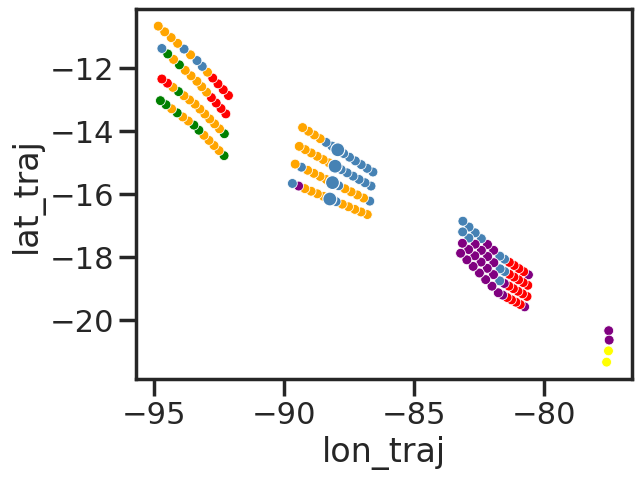

In [ ]:
orbit = '06766E'
tmp = bt_co_back_from_o.where(bt_co_back_from_o.orbit_startpoint == orbit, drop=True)
for i in range(len(tmp.timestep)):
    sns.scatterplot(data = tmp.isel(timestep=i), x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=50)

sns.scatterplot(data = tmp.sel(timestep=0), x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=100)

#### example for presentation

IndexError: index 1 is out of bounds for axis 0 with size 0

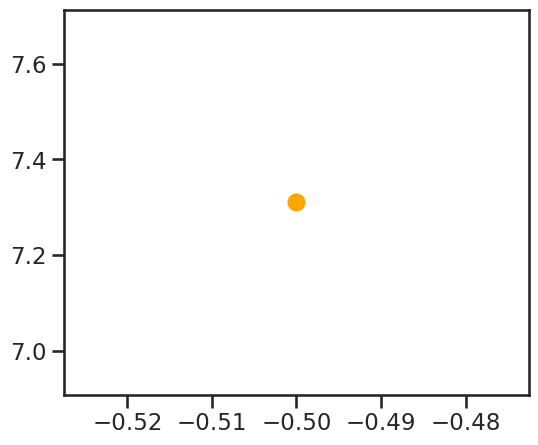

In [33]:
sns.set_context('talk', font_scale=1)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

bt_co_forward_from_c.where(bt_co_forward_from_c.orbit_startpoint == '06766E', drop=True)

plt.figure(figsize=(6, 5))
tmp_c = bt_co_forward_from_c.where(bt_co_forward_from_c.orbit_startpoint == '06766E', drop=True)
#sns.scatterplot(data = tmp_c, x='transition_time_diff', y='rain_rate_cbh', hue='lwp', hue_norm=LogNorm(1e-2, 1e-1), palette='viridis', legend=False, s=100)
tmp_c_sel = tmp_c.where(~np.isnan(tmp_c.transition_time_diff), drop=True).isel(time_startpoint=[9])
plt.plot([tmp_c_sel.transition_time_diff.values], [tmp_c_sel.rwp.values*1e3], 'o', color='orange', markersize=12)

tmp_o = bt_co_back_from_o.where(bt_co_back_from_o.orbit_startpoint == '06766E', drop=True)
#sns.scatterplot(data = tmp_o, x='transition_time_diff', y='rain_rate_cbh', hue='lwp', hue_norm=LogNorm(1e-2, 1e-1), palette='viridis', legend=False, s=100)
tmp_o_sel = tmp_o.where(~np.isnan(tmp_o.transition_time_diff), drop=True).isel(time_startpoint=[1])
plt.plot([tmp_o_sel.transition_time_diff.values], [tmp_o_sel.rwp.values*1e3], 'o', color='deeppink', markersize=12)

plt.yscale('log')
plt.ylim(2e-4, 5e-2)
plt.xlim(-5, 5)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / kg m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')

#sm = plt.cm.ScalarMappable(cmap='viridis', norm=LogNorm(1e-2, 1e-1))
#sm.set_array([])
#cbar = plt.colorbar(sm, ax=plt.gca(), fraction=0.025)
#cbar.set_label('LWP/ kg m$^{-2}$')

1.0
Original shape: FrozenMappingWarningOnValuesAccess({'y': 2712, 'x': 2712, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 548, 'x': 557, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Lat range: -23.19 to -2.12
Lon range: -97.63 to -74.62


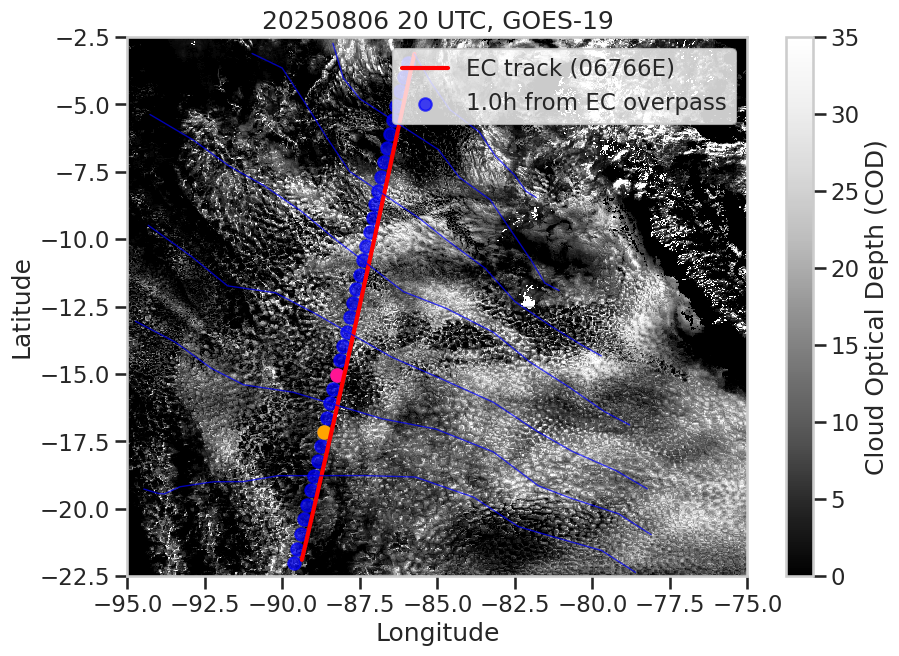

In [ ]:
orbit = '06766E'
bt_orbit = bt_with_goes.where(bt_with_goes.orbit_startpoint == orbit, drop=True)
overpass_date = str(bt_orbit.time_startpoint[0].dt.strftime('%Y%m%d').values)
valid_dates = np.abs(bt_orbit.datetime_traj - bt_orbit.time_startpoint[0]) < np.timedelta64(42, 'h')
bt_orbit = bt_orbit.where(valid_dates)

goes_time = 20
overpass_time = 19
date = overpass_date

timestep = (pd.to_datetime(date+str(goes_time).zfill(2)+'00') - pd.to_datetime(overpass_date+str(overpass_time).zfill(2)+'00')).total_seconds() / 3600
print(timestep)

with xr.open_dataset(f'/home/jmayer/Object_Data/GOES19/goes19_CODF_{date}_{goes_time}00.nc') as ds:
    # Crop to your region
    ds_COD_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

plt.figure(figsize=(10, 7))
plt.pcolormesh(ds_COD_cropped.longitude, ds_COD_cropped.latitude, ds_COD_cropped['COD'], 
            vmax=35, cmap='Greys_r', shading='auto')
plt.colorbar(label='Cloud Optical Depth (COD)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title(f'{date} {goes_time} UTC, GOES-19')

bt_startpoint = bt_orbit.sel(timestep=0)
plt.plot(bt_startpoint.lon_traj.values, bt_startpoint.lat_traj.values, color='red', lw=3, label=f'EC track ({orbit})')

bt_at_sel_timestep = bt_orbit.sel(timestep=timestep)
plt.scatter(bt_at_sel_timestep.lon_traj.values, bt_at_sel_timestep.lat_traj.values, color='blue', marker='o', alpha=0.7, label=f'{timestep}h from EC overpass')

tmp_at_sel_timestep = tmp_c.where(~np.isnan(tmp_c.transition_time_diff), drop=True).sel(timestep=timestep).isel(time_startpoint=[11])
plt.scatter(tmp_at_sel_timestep.lon_traj.values, tmp_at_sel_timestep.lat_traj.values, color='orange', marker='o', alpha=1)

tmp_at_sel_timestep = tmp_o.where(~np.isnan(tmp_o.transition_time_diff), drop=True).sel(timestep=timestep).isel(time_startpoint=[1])
plt.scatter(tmp_at_sel_timestep.lon_traj.values, tmp_at_sel_timestep.lat_traj.values, color='deeppink', marker='o', alpha=1)


for i in range(len(bt_orbit.time_startpoint)//5):
    traj = bt_orbit.isel(time_startpoint=i*5).sortby('timestep')
    plt.plot(traj.lon_traj.values, traj.lat_traj.values, color='blue', lw=1, alpha=0.7)

plt.legend()
plt.ylim(lat_bounds)
plt.xlim(lon_bounds)
plt.show()

Plotting orbit 06766E


Selecting frame from 9 to 4877
Selecting frame from 443 to 11483


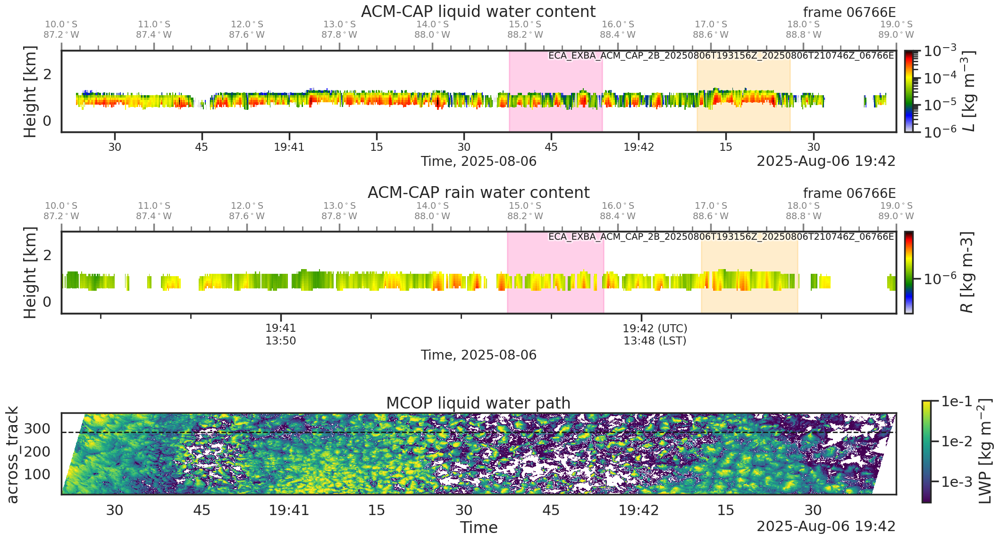

In [67]:
sns.set_style('white')
month = '08'

for orbit in ['06766E']:
    print(f'Plotting orbit {orbit}')

    bt_co_c_orbit = bt_co_c.where(bt_co_c.orbit_startpoint == orbit, drop=True)
    bt_co_o_orbit = bt_co_o.where(bt_co_o.orbit_startpoint == orbit, drop=True)
    bt_co_c_orbit = bt_co_c_orbit.where(~np.isnan(bt_co_c_orbit.transition_time_diff), drop=True).isel(time_startpoint=[11])
    bt_co_o_orbit = bt_co_o_orbit.where(~np.isnan(bt_co_o_orbit.transition_time_diff), drop=True).isel(time_startpoint=[1])

    # load ACMCAP
    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/{month}/*/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
    lat_range = (-19, -10)
    lon_range = (-95, -75)
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_range[0]) & (ACMCAP.latitude < lat_range[1]) & (ACMCAP.longitude > lon_range[0]) & (ACMCAP.longitude < lon_range[1]), drop=True)
    ACMCAP.encoding = encoding.copy()

    # load MCOP
    try:
        filename = glob.glob(f'/home/jmayer/Object_Data/MSI_COP_2A/2025/{month}/*/*_{orbit}.h5')[0]
        MCOP = ecio.load_MCOP(filename)
        MCOP = MCOP.assign_coords(
            {
            'along_track': (
                ["along_track"],
                MCOP['along_track'].data,
                MCOP['along_track'].attrs
                ),
            'across_track': (
                ['across_track'],
                MCOP['across_track'].data,
                MCOP['across_track'].attrs
                )
            })
        MCOP2 = MCOP.where((MCOP.latitude > lat_range[0]) & (MCOP.latitude < lat_range[1]) & (MCOP.longitude > lon_range[0]) & (MCOP.longitude < lon_range[1]), drop=True)
        MCOP2 = MCOP2[['latitude','longitude','cloud_water_path','cloud_optical_thickness','cloud_effective_radius']]
        MCOP2['time'] = MCOP['time'].sel(along_track=MCOP2.along_track)
        MCOP2 = MCOP2.assign_coords(
            {
            'time': (
                ['along_track'],
                MCOP2.time.data,
                MCOP2.time.attrs
                )
            })
        MCOP2 = MCOP2.swap_dims({'along_track': 'time'})
    except:
        print(f'No MCOP data for {orbit}')
        MCOP2 = None

    # plot
    fig, axs = plt.subplots(3,1, figsize=(20,12), gridspec_kw={'height_ratios': [1, 1, 1]})

    # highlight scenes for which transitions were found
    for ax in axs[0:2]:
        for i in range(len(bt_co_c_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_c_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='orange', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_c_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            #ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            #ax.annotate(bt_co_c_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    for ax in axs[0:2]:
        for i in range(len(bt_co_o_orbit.lat_min_acmcap)):
            time_0 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_min_acmcap[i] - ACMCAP.latitude).argmin()].values
            time_1 = ACMCAP.time[np.abs(bt_co_o_orbit.lat_max_acmcap[i] - ACMCAP.latitude).argmin()].values
            ax.axvspan(time_0, time_1, color='deeppink', alpha=0.2)
            time_startpoint = ACMCAP.time[np.abs(bt_co_o_orbit.sel(timestep=0).lat_traj[i] - ACMCAP.latitude).argmin()].values
            #ax.plot([time_startpoint], [3000], 'ro', markersize=8)
            #ax.annotate(bt_co_o_orbit.transition_time_diff[i].values, xy=(time_startpoint, 3200), fontsize=12)

    ax = axs[0]
    ecplt.plot_EC_2D(ax, ACMCAP, 'liquid_water_content', "$L$", units="kg m$^{-3}$", plot_scale='log', plot_range=[1e-6,1e-3], cmap='chiljet2', hmax=3000)

    ax = axs[1]
    ecplt.plot_EC_2D(ax, ACMCAP, 'rain_water_content', "$R$", hmax=3000)

    if MCOP2 is not None:
        ax = axs[2]
        ax.sharex(axs[0])
        (np.log(MCOP2.cloud_water_path)).T.plot(ax=ax, cmap='viridis', vmax=-3.2, vmin=-1, add_colorbar=False)
        ax.axhline(284, color='k', linestyle='--', lw=2)
        ax.set_title('MCOP liquid water path')
        # add cbar to the right
        cbar_ax = fig.add_axes([0.99, 0.09, 0.009, 0.18])  # [left, bottom, width, height]
        cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
        cbar.set_label('LWP [kg m$^{-2}$]')
        cbar.set_ticks([-3,-2,-1])
        cbar.set_ticklabels(['1e-3', '1e-2', '1e-1'])
    fig.tight_layout()
    plt.show()

Plotting orbit 06704E
Selecting frame from 6 to 4874
Selecting frame from 433 to 11472


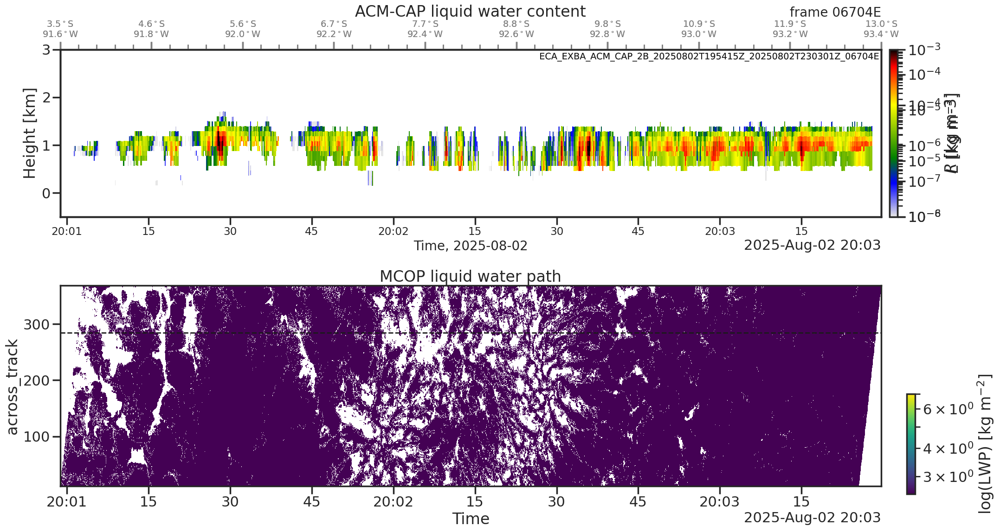

In [ ]:
bt_co_c = bt_co_forward_from_c.where(~np.isnan(bt_co_forward_from_c.transition_time_diff), drop=True)
bt_co_o = bt_co_back_from_o.where(~np.isnan(bt_co_back_from_o.transition_time_diff), drop=True)

orbits_c = np.unique(bt_co_c.orbit_startpoint)
orbits_o = np.unique(bt_co_o.orbit_startpoint)
orbits = np.unique(np.concatenate((orbits_c, orbits_o)))
#orbit = orbits[0]
month = '08'

for orbit in ['06704E']: # ['06766E']: 
    print(f'Plotting orbit {orbit}')

    # load ACMCAP
    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/2025/{month}/*/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
    lat_range = (-13, -3.5)
    lon_range = (-95, -75)
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_range[0]) & (ACMCAP.latitude < lat_range[1]) & (ACMCAP.longitude > lon_range[0]) & (ACMCAP.longitude < lon_range[1]), drop=True)
    ACMCAP.encoding = encoding.copy()

    # load MCOP
    try:
        filename = glob.glob(f'/home/jmayer/Object_Data/MSI_COP_2A/2025/{month}/*/*_{orbit}.h5')[0]
        MCOP = ecio.load_MCOP(filename)
        MCOP = MCOP.assign_coords(
            {
            'along_track': (
                ["along_track"],
                MCOP['along_track'].data,
                MCOP['along_track'].attrs
                ),
            'across_track': (
                ['across_track'],
                MCOP['across_track'].data,
                MCOP['across_track'].attrs
                )
            })
        MCOP2 = MCOP.where((MCOP.latitude > lat_range[0]) & (MCOP.latitude < lat_range[1]) & (MCOP.longitude > lon_range[0]) & (MCOP.longitude < lon_range[1]), drop=True)
        MCOP2 = MCOP2[['latitude','longitude','cloud_water_path','cloud_optical_thickness','cloud_effective_radius']]
        MCOP2['time'] = MCOP['time'].sel(along_track=MCOP2.along_track)
        MCOP2 = MCOP2.assign_coords(
            {
            'time': (
                ['along_track'],
                MCOP2.time.data,
                MCOP2.time.attrs
                )
            })
        MCOP2 = MCOP2.swap_dims({'along_track': 'time'})
    except:
        print(f'No MCOP data for {orbit}')
        MCOP2 = None

    # plot
    fig, axs = plt.subplots(2,1, figsize=(20,10), gridspec_kw={'height_ratios': [1, 1]})

    ax = axs[0]
    ecplt.plot_EC_2D(ax, ACMCAP, 'rain_water_content', "$R$", cmap='Blues', plot_range=[1e-6,1e-3], hmax=3000)
    ax.collections[0].colorbar.remove()
    ecplt.plot_EC_2D(ax, ACMCAP, 'liquid_water_content', "$L$", units="kg m$^{-3}$", plot_scale='log', plot_range=[1e-6,1e-3], cmap='chiljet2', hmax=3000)

    lcl = acmcap[(acmcap.orbit == orbit) & (acmcap.latitude > -13) & (acmcap.latitude < -3.5)].lcl.values
    time = acmcap[(acmcap.orbit == orbit) & (acmcap.latitude > -13) & (acmcap.latitude < -3.5)].time.values
    plt.plot(time, lcl, color='black', lw=1, label='LCL')

    if MCOP2 is not None:
        ax = axs[1]
        ax.sharex(axs[0])
        MCOP2.cloud_water_path.T.plot(ax=ax, cmap='viridis', norm=LogNorm(vmin=1e-2, vmax=1e0), add_colorbar=False)
        ax.axhline(284, color='k', linestyle='--', lw=2)
        ax.set_title('MCOP liquid water path')
        # add cbar to the right
        cbar_ax = fig.add_axes([0.99, 0.12, 0.009, 0.3])  # [left, bottom, width, height]
        cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
        cbar.set_label('LWP [kg m$^{-2}$]')
    fig.tight_layout()
    plt.show()

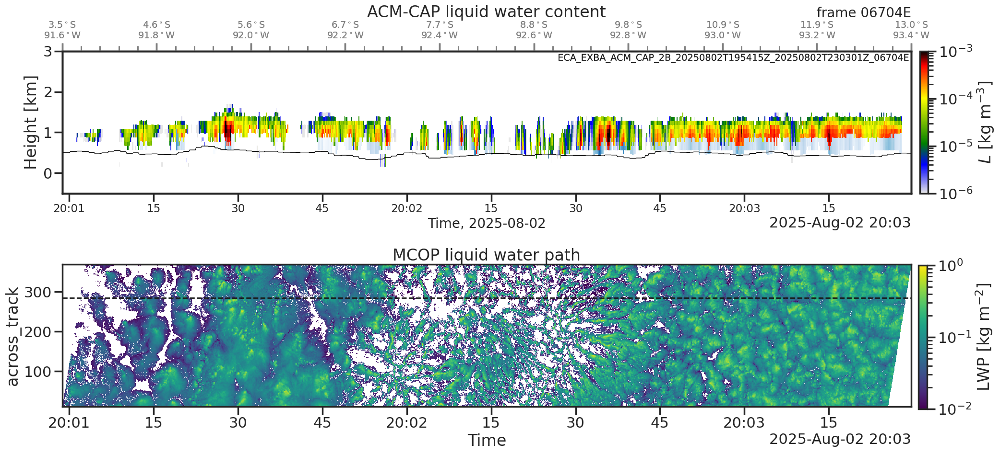

In [42]:
fig, axs = plt.subplots(2,1, figsize=(20,10), gridspec_kw={'height_ratios': [1, 1]})

ax = axs[0]
ecplt.plot_EC_2D(ax, ACMCAP, 'rain_water_content', "$R$", cmap='Blues', plot_range=[1e-6,1e-3], hmax=3000)
ax.collections[0].colorbar.remove()
ecplt.plot_EC_2D(ax, ACMCAP, 'liquid_water_content', "$L$", units="kg m$^{-3}$", plot_scale='log', plot_range=[1e-6,1e-3], cmap='chiljet2', hmax=3000)

lcl = acmcap[(acmcap.orbit == orbit) & (acmcap.latitude > -13) & (acmcap.latitude < -3.5)].lcl.values
time = acmcap[(acmcap.orbit == orbit) & (acmcap.latitude > -13) & (acmcap.latitude < -3.5)].time.values
plt.plot(time, lcl, color='black', lw=1, label='LCL')

if MCOP2 is not None:
    ax = axs[1]
    ax.sharex(axs[0])
    MCOP2.cloud_water_path.T.plot(ax=ax, cmap='viridis', norm=LogNorm(vmin=1e-2, vmax=1e0), add_colorbar=False)
    ax.axhline(284, color='k', linestyle='--', lw=2)
    ax.set_title('MCOP liquid water path')
    # add cbar to the right
    cbar_ax = fig.add_axes([0.97, 0.12, 0.009, 0.3])  # [left, bottom, width, height]
    cbar = fig.colorbar(ax.collections[0], cax=cbar_ax)
    cbar.set_label('LWP [kg m$^{-2}$]')
fig.tight_layout()
plt.show()

### OC transitions

In [58]:
bt_oc_forward_from_o = add_acmcap_info_to_bt(bt_oc_forward_from_o, acmcap, transition_from_goes_cats=[2])

2025-07-01T19:54:36.605387008
No CATS = [2] match found
2025-07-01T19:54:44.669450944
No CATS = [2] match found
2025-07-01T19:54:52.733513920
No CATS = [2] match found
2025-07-01T19:55:00.797578048
No CATS = [2] match found
2025-07-01T19:55:08.861642048
No CATS = [2] match found
2025-07-01T19:55:16.925705088
No CATS = [2] match found
2025-07-01T19:55:24.989771968
No CATS = [2] match found
2025-07-01T19:55:33.053838912
No CATS = [2] match found
2025-07-01T19:55:41.117903104
No CATS = [2] match found
2025-07-01T19:55:49.181966464
No CATS = [2] match found
2025-07-01T19:55:57.246030080
No CATS = [2] match found
2025-07-01T19:56:05.310094016
No CATS = [2] match found
2025-07-01T19:56:13.374157056
No CATS = [2] match found
2025-07-01T19:56:21.438221056
No CATS = [2] match found
2025-07-01T19:56:29.502284032
No CATS = [2] match found
2025-07-01T19:56:37.566348032
No CATS = [2] match found
2025-07-01T19:56:45.630411904
No CATS = [2] match found
2025-07-01T19:56:53.694474880
No CATS = [2] matc

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


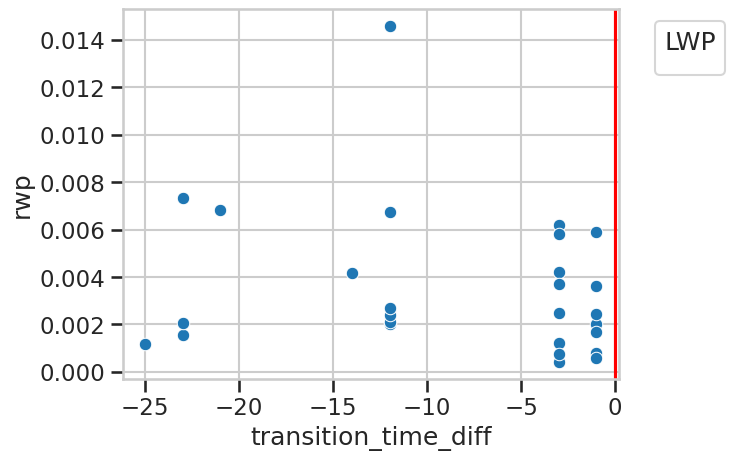

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


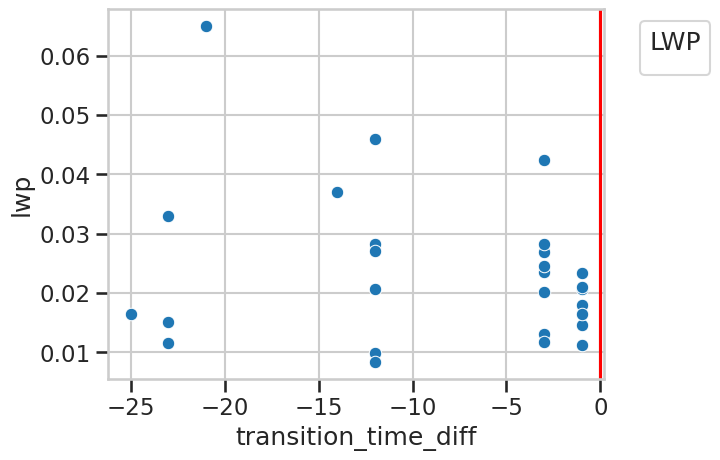

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


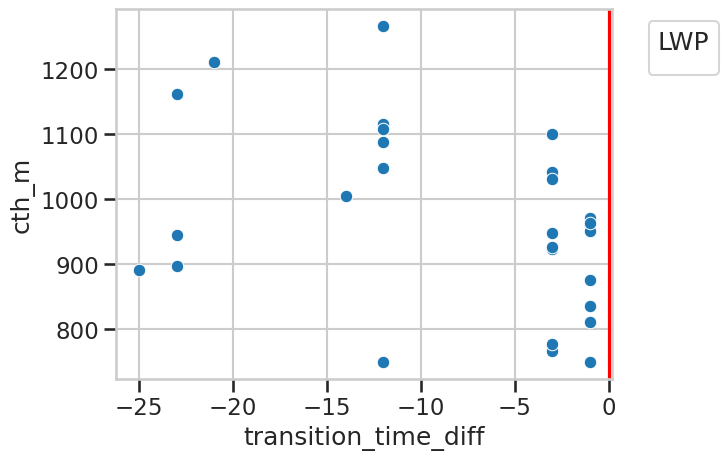

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


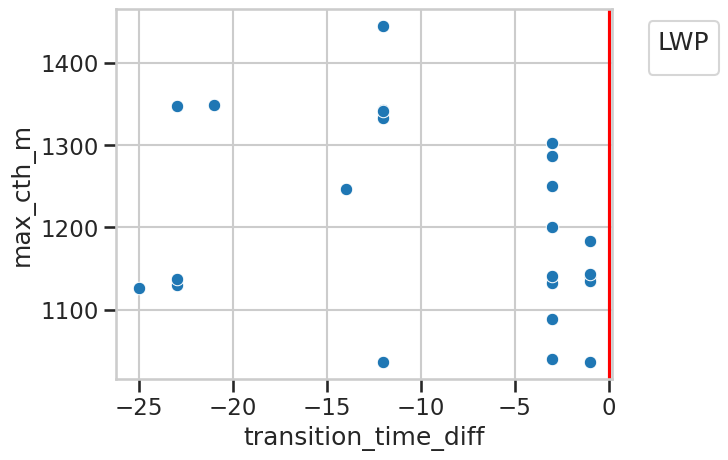

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


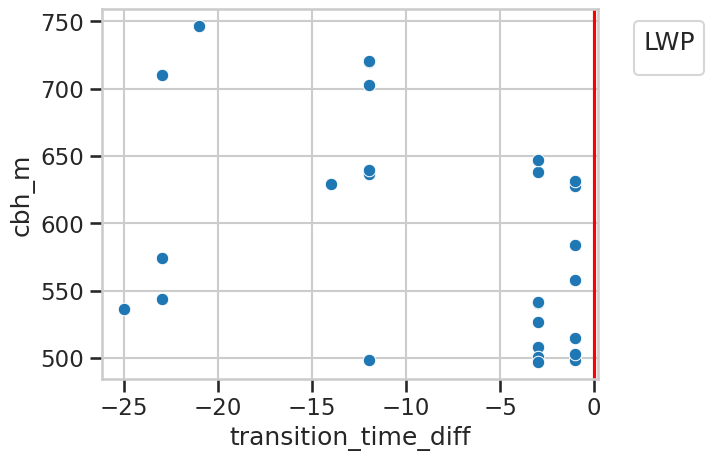

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


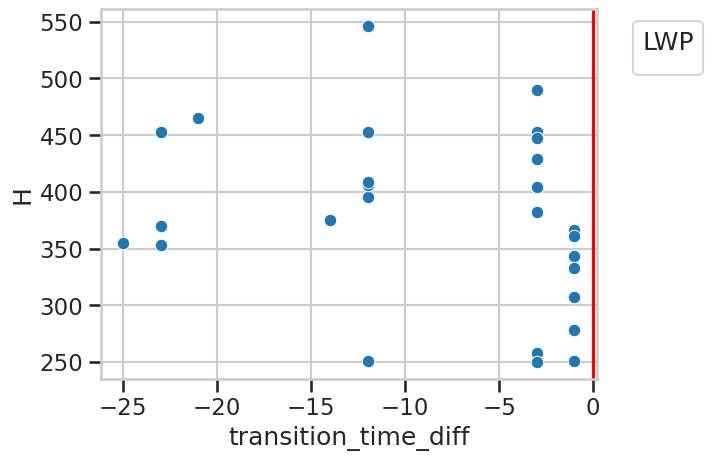

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


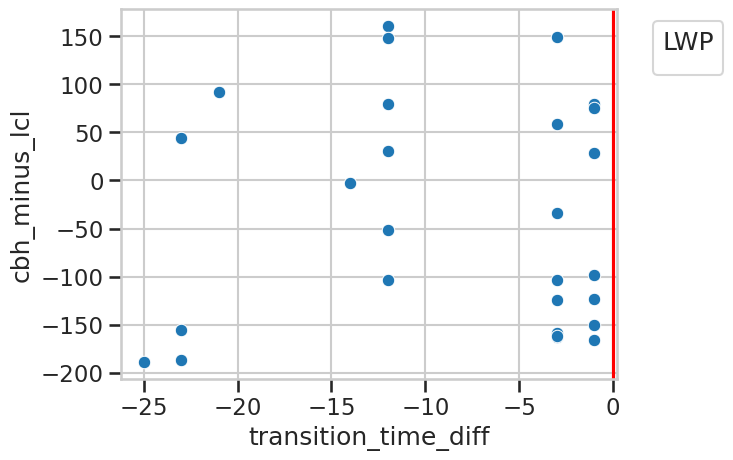

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


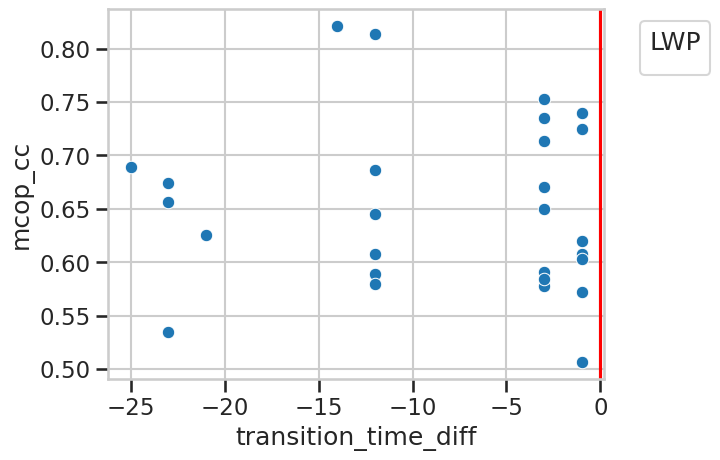

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


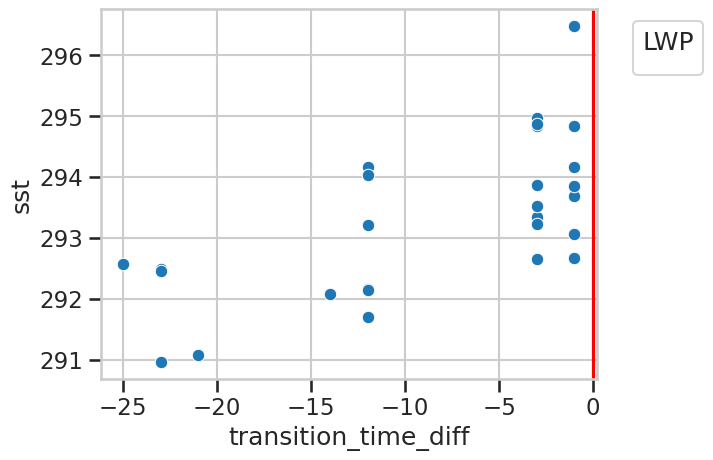

/tmp/ipykernel_4192883/843942413.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')


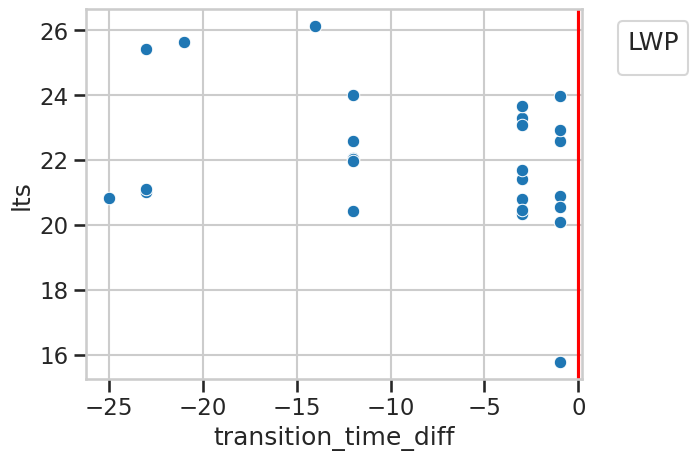

In [59]:
sns.set_context('talk', font_scale=1)
sns.set_style('whitegrid')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False
for var in ['rwp', 'lwp', 'cth_m','max_cth_m', 'cbh_m', 'H', 'cbh_minus_lcl', 'mcop_cc', 'sst', 'lts']:
    sns.scatterplot(data = bt_oc_forward_from_o, x='transition_time_diff', y=var)#, hue='orbit_startpoint', palette='tab10', legend=True, s=100)
    
    plt.legend(title='LWP', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.axvline(0, color='red', linestyle='-')
    plt.show()